# Projet Deep Learning : Reconnaissance et analyse automatique de panneaux de signalisation

## Partie 1 - Recherche, compréhension et préparation des données

### 1.1 Description du dataset

Nous utilisons un dataset de détection d'objets, "Yolo to COCO Computer Vision Dataset" publié sur Roboflow : https://universe.roboflow.com/yolo-to-coco-ca2en/yolo-to-coco-kpv56

- Auteurs : "Yolo to COCO", compte anonyme sur Robolow.
- Licence : CC BY 4.0

Il contient des photos de scènes routières. Chaque panneau visible est annoté par une boite (bounding box) et une classe. Une même photo peut donc contenir plusieurs panneaux, de classes différentes.
- Pour la classification (parties 1 à 6), nous découperons chaque boîte : un panneau = une image à classer.
- Pour la détection (partie 8), nous utiliserons les photos entières avec leurs boîtes.

Le dataset fournit une séparation train / valid / test, mais elle n'est pas stratifiée : nous la refaisons dans la partie 1.2. Nous avons copié le jeu de données dans notre espace Roboflow et le téléchargeons dans notre environement de travail à chaque éxecution.

In [ ]:
!pip install -q roboflow

from google.colab import userdata
from roboflow import Roboflow

"""
Puisque nous éxecutons le notebook sur Colab, le dataset est téléchargé à chaque reprise.
Vous devriez télécharger le dataset manuelement, ou générer un snippet similair avec votre propre mot de passe API.
Il est nécessaire que vous forkiez le dataset dans les deux cas.
"""

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
project = rf.workspace("efe-tatar").project("yolo-to-coco-traffic-signs-pmo2q")
dataset = project.version(1).download("coco")

datasetDirectory = dataset.location
print(datasetDirectory)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 1.6 MB/s eta 0:00:00a 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 20.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.5 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to YOLO-to-COCO-Traffic-Signs-1 in coco:: 100%|██████████| 3057/3057 [00:00<00:00, 6864.57it/s]

/content/YOLO-to-COCO-Traffic-Signs-1


In [2]:
import json
import os

splitNames = ["train", "valid", "test"]

# one COCO annotation file per split
cocoOfSplit = {}
for splitName in splitNames:
    with open(os.path.join(datasetDirectory, splitName, "_annotations.coco.json")) as jsonFile:
        cocoOfSplit[splitName] = json.load(jsonFile)

# every box of the dataset, with its split, its image and its class
boxes = []
for splitName in splitNames:
    coco = cocoOfSplit[splitName]

    categoryName = {}
    for category in coco["categories"]:
        categoryName[category["id"]] = category["name"]

    fileOfImage = {}
    for image in coco["images"]:
        fileOfImage[image["id"]] = image["file_name"]

    for annotation in coco["annotations"]:
        x, y, width, height = annotation["bbox"]
        boxes.append({
            "split": splitName,
            "imageId": annotation["image_id"],
            "file": fileOfImage[annotation["image_id"]],
            "class": categoryName[annotation["category_id"]],
            "x": x,
            "y": y,
            "width": width,
            "height": height,
        })

totalImages = 0
for splitName in splitNames:
    totalImages += len(cocoOfSplit[splitName]["images"])

for splitName in splitNames:
    numberOfImages = len(cocoOfSplit[splitName]["images"])
    numberOfBoxes = len(cocoOfSplit[splitName]["annotations"])
    print(splitName, ":", numberOfImages, "images (", round(100 * numberOfImages / totalImages), "% ),", numberOfBoxes, "boxes")

print("total :", totalImages, "images,", len(boxes), "boxes")
print("boxes per image on average:", round(len(boxes) / totalImages, 2))

train : 2254 images ( 74 % ), 4466 boxes
valid : 556 images ( 18 % ), 1037 boxes
test : 243 images ( 8 % ), 480 boxes
total : 3053 images, 5983 boxes
boxes per image on average: 1.96


#### Les classes

Chaque nom de classe commence par la famille du panneau, suivie de sa signification :

| Préfixe | Famille | Exemples |
|---|---|---|
| `forb_` | Interdiction | `forb_speed_over_50` (vitesse limitée à 50 km/h), `forb_overtake` (interdiction de dépasser) |
| `mand_` | Obligation | `mand_right` (tourner à droite), `mand_roundabout` (giratoire) |
| `warn_` | Danger | `warn_children` (enfants), `warn_slippery_road` (chaussée glissante) |
| `prio_` | Priorité | `prio_stop`, `prio_give_way` (cédez le passage) |
| `info_` | Indication | `info_parking`, `info_bus_station` (arrêt de bus) |

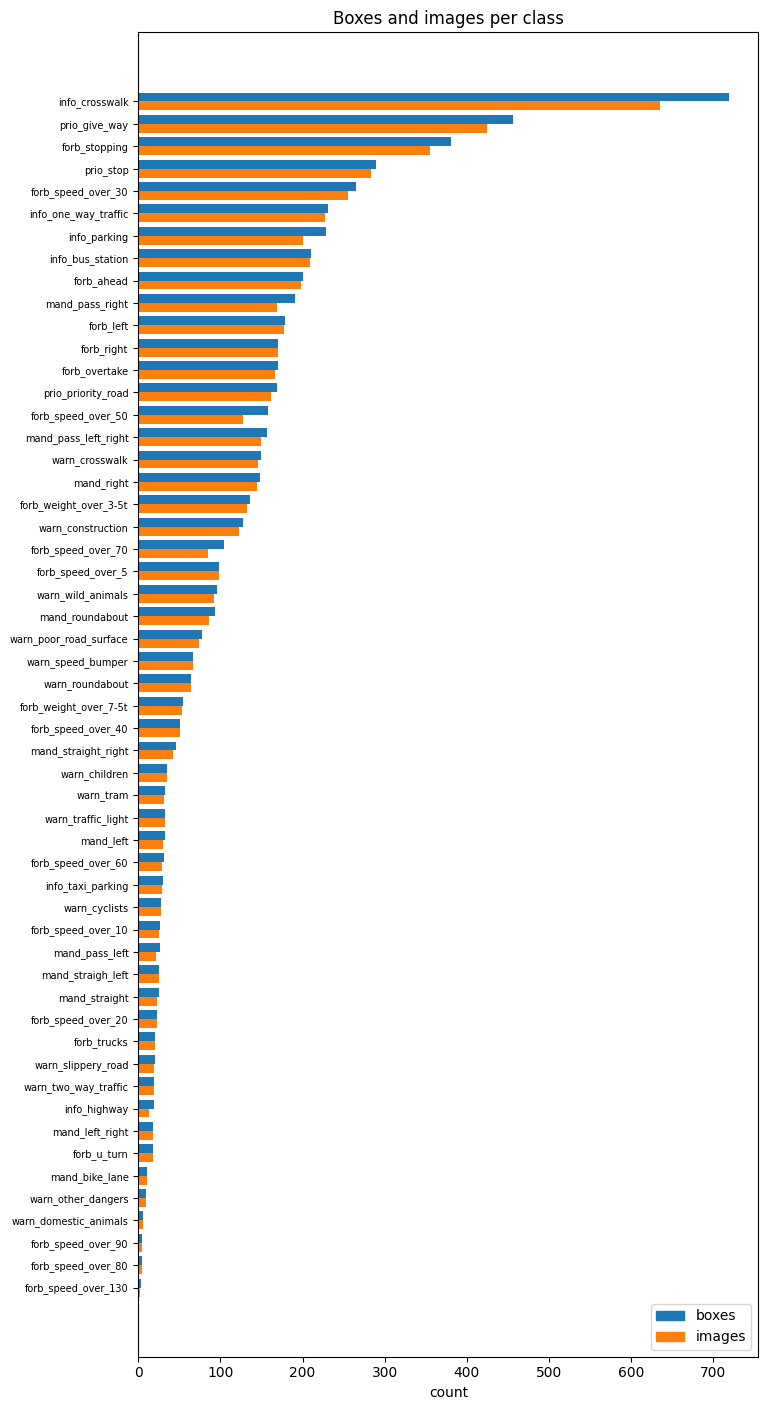

images with more than one class: 1672 out of 3053


In [3]:
import matplotlib.pyplot as plt

classNames = []
for box in boxes:
    if box["class"] not in classNames:
        classNames.append(box["class"])

# a box is one sign to classify; an image can contain several boxes, so we count both
boxesPerClass = {}
imagesPerClass = {}
for box in boxes:
    className = box["class"]
    if className not in boxesPerClass:
        boxesPerClass[className] = 0
        imagesPerClass[className] = set()
    boxesPerClass[className] += 1
    imagesPerClass[className].add((box["split"], box["imageId"]))

sortedClasses = sorted(classNames, key=boxesPerClass.get, reverse=True)

figure, axis = plt.subplots(figsize=(8, len(sortedClasses) * 0.3 + 1))
for i in range(len(sortedClasses)):
    className = sortedClasses[i]
    axis.barh(i - 0.2, boxesPerClass[className], height=0.4, color="tab:blue")
    axis.barh(i + 0.2, len(imagesPerClass[className]), height=0.4, color="tab:orange")

axis.set_yticks(range(len(sortedClasses)))
axis.set_yticklabels(sortedClasses, fontsize=7)
axis.invert_yaxis()
axis.set_xlabel("count")
axis.set_title("Boxes and images per class")
axis.legend([plt.Rectangle((0, 0), 1, 1, color="tab:blue"), plt.Rectangle((0, 0), 1, 1, color="tab:orange")], ["boxes", "images"], loc="lower right")
plt.show()

# images that contain more than one class
classesOfImage = {}
for box in boxes:
    image = (box["split"], box["imageId"])
    if image not in classesOfImage:
        classesOfImage[image] = set()
    classesOfImage[image].add(box["class"])

severalClasses = 0
for image in classesOfImage:
    if len(classesOfImage[image]) > 1:
        severalClasses += 1
print("images with more than one class:", severalClasses, "out of", totalImages)

box width  : min 5 / median 50 / max 608
box height : min 5 / median 56 / max 588


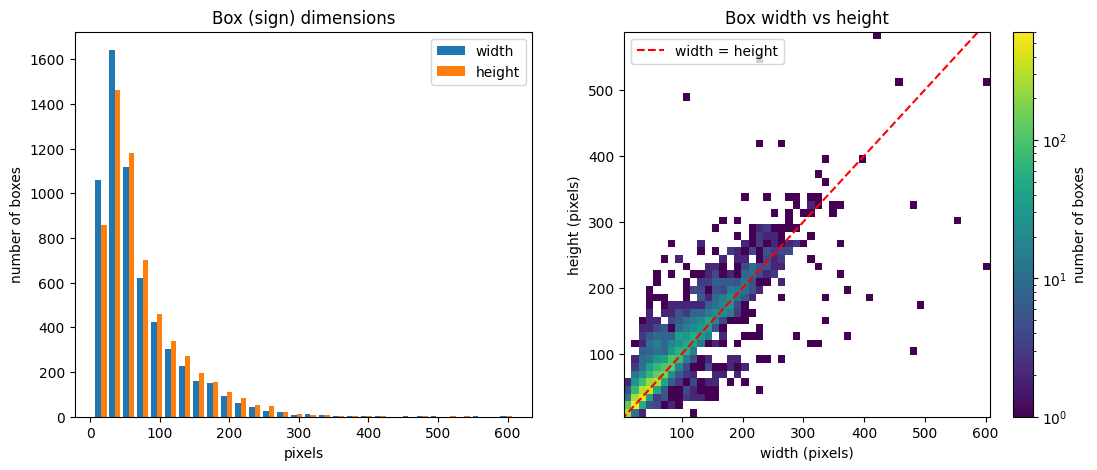

In [4]:
# size of the boxes: these are the signs that will be classified
boxWidths = []
boxHeights = []
for box in boxes:
    boxWidths.append(box["width"])
    boxHeights.append(box["height"])

print("box width  : min", round(min(boxWidths)), "/ median", round(sorted(boxWidths)[len(boxWidths) // 2]), "/ max", round(max(boxWidths)))
print("box height : min", round(min(boxHeights)), "/ median", round(sorted(boxHeights)[len(boxHeights) // 2]), "/ max", round(max(boxHeights)))

figure, (histogramPlot, heatmapPlot) = plt.subplots(1, 2, figsize=(13, 5))

histogramPlot.hist([boxWidths, boxHeights], bins=30, label=["width", "height"])
histogramPlot.set_title("Box (sign) dimensions")
histogramPlot.set_xlabel("pixels")
histogramPlot.set_ylabel("number of boxes")
histogramPlot.legend()

# colour = number of boxes with this width and height (log scale, empty cells left white)
_, _, _, heatmap = heatmapPlot.hist2d(boxWidths, boxHeights, bins=50, cmap="viridis", cmin=1, norm="log")
figure.colorbar(heatmap, ax=heatmapPlot, label="number of boxes")

# boxes on this line are square
biggest = max(max(boxWidths), max(boxHeights))
heatmapPlot.plot([0, biggest], [0, biggest], "--", color="red", label="width = height")
heatmapPlot.set_title("Box width vs height")
heatmapPlot.set_xlabel("width (pixels)")
heatmapPlot.set_ylabel("height (pixels)")
heatmapPlot.legend()

plt.show()

In [5]:
from PIL import Image

# file type and colour mode (RGB = colour, 3 channels; L = greyscale; RGBA = colour + transparency)
fileTypes = {}
colourModes = {}
for splitName in splitNames:
    for image in cocoOfSplit[splitName]["images"]:
        fileType = os.path.splitext(image["file_name"])[1].lower()
        fileTypes[fileType] = fileTypes.get(fileType, 0) + 1

        with Image.open(os.path.join(datasetDirectory, splitName, image["file_name"])) as photo:
            colourModes[photo.mode] = colourModes.get(photo.mode, 0) + 1

print("file types:", fileTypes)
print("colour modes:", colourModes)

file types: {'.jpg': 3053}
colour modes: {'RGB': 3053}


#### Dimensions et format

- **Format :** les 3 053 photos sont des fichiers **JPG en couleur (RGB, 3 canaux)**.
- **Dimensions des photos :** toutes les photos ont la même taille, 640 × 640 pixels.
- **Dimensions des panneaux :** ce sont les boîtes qui seront classées, et elles ont des tailles très variables : de 5 à 608 pixels de large, avec une médiane d'environ 50 × 56 pixels. La carte de chaleur montre que la plupart des boîtes sont proches de la diagonale (panneaux à peu près carrés) et petites. Il faudra donc **redimensionner** tous les panneaux à une taille commune avant de les donner à un réseau de neurones.

In [6]:
# class imbalance
mostFrequent = sortedClasses[0]
leastFrequent = sortedClasses[-1]
averageBoxes = len(boxes) / len(classNames)

print("most frequent :", mostFrequent, boxesPerClass[mostFrequent], "boxes")
print("least frequent:", leastFrequent, boxesPerClass[leastFrequent], "boxes")
print("ratio:", round(boxesPerClass[mostFrequent] / boxesPerClass[leastFrequent], 1))
print("average per class:", round(averageBoxes))

rareClasses = []
for className in sortedClasses:
    if boxesPerClass[className] < averageBoxes / 2:
        rareClasses.append(className)
print(len(rareClasses), "classes have less than half the average:", ", ".join(rareClasses))

most frequent : info_crosswalk 719 boxes
least frequent: forb_speed_over_130 3 boxes
ratio: 239.7
average per class: 111
27 classes have less than half the average: forb_weight_over_7-5t, forb_speed_over_40, mand_straight_right, warn_children, warn_tram, warn_traffic_light, mand_left, forb_speed_over_60, info_taxi_parking, warn_cyclists, forb_speed_over_10, mand_pass_left, mand_straigh_left, mand_straight, forb_speed_over_20, forb_trucks, warn_slippery_road, warn_two_way_traffic, info_highway, mand_left_right, forb_u_turn, mand_bike_lane, warn_other_dangers, warn_domestic_animals, forb_speed_over_90, forb_speed_over_80, forb_speed_over_130


In [7]:
# boxes per class in each split, from the rarest class to the most frequent
boxesPerSplit = {}
for className in classNames:
    boxesPerSplit[className] = {"train": 0, "valid": 0, "test": 0}
for box in boxes:
    boxesPerSplit[box["class"]][box["split"]] += 1

print("class".ljust(26), "train".rjust(6), "valid".rjust(6), "test".rjust(5), "total".rjust(6))
for className in reversed(sortedClasses):
    counts = boxesPerSplit[className]
    print(className.ljust(26), str(counts["train"]).rjust(6), str(counts["valid"]).rjust(6), str(counts["test"]).rjust(5), str(boxesPerClass[className]).rjust(6))

class                       train  valid  test  total
forb_speed_over_130             0      1     2      3
forb_speed_over_80              4      0     0      4
forb_speed_over_90              5      0     0      5
warn_domestic_animals           6      0     0      6
warn_other_dangers              7      2     0      9
mand_bike_lane                  8      2     1     11
forb_u_turn                    11      5     2     18
mand_left_right                16      2     0     18
info_highway                    8      7     4     19
warn_two_way_traffic           13      2     4     19
warn_slippery_road             19      1     0     20
forb_trucks                    18      2     0     20
forb_speed_over_20             15      1     7     23
mand_straight                  17      5     3     25
mand_straigh_left              25      0     0     25
mand_pass_left                 22      2     2     26
forb_speed_over_10             21      2     3     26
warn_cyclists               

#### Déséquilibre des classes

Le jeu est **fortement déséquilibré** : `info_crosswalk` a 719 boîtes alors que `forb_speed_over_130` n'en a que 3, soit un rapport de 240. La moyenne est de 111 boîtes par classe, et 27 classes sur 54 sont sous la moitié de cette moyenne.

Conséquences :
- un modèle peut obtenir une bonne **accuracy** en réussissant surtout les grandes classes. Nous suivrons donc aussi le **F1 macro**, où chaque classe compte autant, quelle que soit sa taille ;
- certaines classes sont trop rares pour être apprises ou évaluées ;
- la séparation train / valid / test fournie par Roboflow **n'est pas stratifiée** : le tableau ci-dessus montre des classes sans aucun exemple en train (`forb_speed_over_130`), en validation (`mand_straigh_left`, `forb_speed_over_60`) ou en test (`mand_left_right`, `forb_trucks`, `warn_slippery_road`). On ne pourrait ni apprendre ni évaluer ces classes correctement. Nous refaisons donc la séparation dans la partie 1.2.

### 1.2 Préparation des données

Rôle de chaque étape :

1. **Seuil de 15 boîtes par classe.** Les classes plus rares ne peuvent être ni apprises ni évaluées de façon fiable. Le seuil se place sur une coupure naturelle de la distribution (rien entre 12 et 17 boîtes) : il retire 6 classes et seulement 38 boîtes sur 5 983 (0,6 %). Il reste **48 classes**. Limite : le modèle ne reconnaîtra pas ces 6 panneaux.
2. **Nouvelle séparation train / validation / test (70 / 15 / 15), par photo.**
   - *Par photo :* tous les panneaux d'une même photo vont dans le même ensemble, sinon deux panneaux du même cliché (même lumière, même angle) pourraient se retrouver en train et en test, et le score de test serait trop optimiste.
   - *Stratifiée :* on traite les classes de la plus rare à la plus fréquente et on répartit leurs photos en 70 / 15 / 15, pour que chaque classe soit présente dans les trois ensembles.
   - *Rôle des ensembles :* **train** pour apprendre les poids, **validation** pour comparer les modèles et choisir les réglages, **test** pour la seule évaluation finale. Le test n'est jamais utilisé pour faire un choix.
3. **Découpage :** chaque boîte est découpée dans sa photo, ce qui donne une image par panneau.
4. **Redimensionnement à 32 × 32 :** un réseau de neurones attend des entrées de taille fixe. 32 × 32 est proche de la taille médiane des panneaux (environ 50 px), donc on perd peu de détail, et c'est la taille classique du benchmark GTSRB. Les panneaux sont étirés plutôt que complétés par des bandes : la plupart sont déjà presque carrés, et des bandes ajoutées seraient un indice artificiel.
5. **Normalisation :** les pixels passent de 0–255 à 0–1. Des entrées de petite amplitude rendent l'apprentissage plus stable (gradients de taille raisonnable).
6. **Préparation et encodage des labels :** chaque nom de classe devient un entier de 0 à 47 (ordre alphabétique). Un encodage *one-hot* n'est **pas nécessaire** : la perte `sparse_categorical_crossentropy` travaille directement avec des entiers.

In [8]:
minimumBoxes = 15

# classes from the rarest to the most frequent
keptClasses = []
removedBoxes = 0
for className in reversed(sortedClasses):
    if boxesPerClass[className] >= minimumBoxes:
        keptClasses.append(className)
    else:
        removedBoxes += boxesPerClass[className]
        print("removed:", className, boxesPerClass[className], "boxes")

print("\n", len(keptClasses), "classes kept,", removedBoxes, "boxes removed out of", len(boxes))

removed: forb_speed_over_130 3 boxes
removed: forb_speed_over_80 4 boxes
removed: forb_speed_over_90 5 boxes
removed: warn_domestic_animals 6 boxes
removed: warn_other_dangers 9 boxes
removed: mand_bike_lane 11 boxes

 48 classes kept, 38 boxes removed out of 5983


In [9]:
import random

# only the boxes of the kept classes
keptBoxes = []
for box in boxes:
    if box["class"] in keptClasses:
        keptBoxes.append(box)

# a photo is identified by its original split and its id
photosOfClass = {}
for className in keptClasses:
    photosOfClass[className] = []
for box in keptBoxes:
    photo = (box["split"], box["imageId"])
    if photo not in photosOfClass[box["class"]]:
        photosOfClass[box["class"]].append(photo)

# from the rarest class to the most frequent, the photos not placed yet are split 70 / 15 / 15
# all the boxes of a photo go in the same set
random.seed(42)
setOfPhoto = {}
for className in keptClasses:
    photos = []
    for photo in photosOfClass[className]:
        if photo not in setOfPhoto:
            photos.append(photo)

    random.shuffle(photos)
    trainEnd = int(0.70 * len(photos))
    validEnd = int(0.85 * len(photos))

    for i in range(len(photos)):
        if i < trainEnd:
            setOfPhoto[photos[i]] = "train"
        elif i < validEnd:
            setOfPhoto[photos[i]] = "valid"
        else:
            setOfPhoto[photos[i]] = "test"

for box in keptBoxes:
    box["set"] = setOfPhoto[(box["split"], box["imageId"])]

In [10]:
# boxes per class in each new set, from the rarest class to the most frequent
newBoxesPerSet = {}
for className in keptClasses:
    newBoxesPerSet[className] = {"train": 0, "valid": 0, "test": 0}
for box in keptBoxes:
    newBoxesPerSet[box["class"]][box["set"]] += 1

print("class".ljust(26), "train".rjust(6), "valid".rjust(6), "test".rjust(5), "total".rjust(6))
for className in keptClasses:
    counts = newBoxesPerSet[className]
    print(className.ljust(26), str(counts["train"]).rjust(6), str(counts["valid"]).rjust(6), str(counts["test"]).rjust(5), str(boxesPerClass[className]).rjust(6))

photosPerSet = {"train": 0, "valid": 0, "test": 0}
for photo in setOfPhoto:
    photosPerSet[setOfPhoto[photo]] += 1

boxesPerSet = {"train": 0, "valid": 0, "test": 0}
for box in keptBoxes:
    boxesPerSet[box["set"]] += 1

print()
for setName in ["train", "valid", "test"]:
    print(setName, ":", photosPerSet[setName], "images (", round(100 * photosPerSet[setName] / len(setOfPhoto)), "% ),", boxesPerSet[setName], "boxes")

class                       train  valid  test  total
forb_u_turn                    12      3     3     18
mand_left_right                12      3     3     18
info_highway                   15      2     2     19
warn_two_way_traffic           13      3     3     19
warn_slippery_road             14      3     3     20
forb_trucks                    14      3     3     20
forb_speed_over_20             16      3     4     23
mand_straight                  16      3     6     25
mand_straigh_left              17      4     4     25
mand_pass_left                 20      3     3     26
forb_speed_over_10             18      4     4     26
warn_cyclists                  18      4     6     28
info_taxi_parking              21      4     5     30
forb_speed_over_60             21      5     5     31
mand_left                      23      4     5     32
warn_traffic_light             21      6     5     32
warn_tram                      21      5     7     33
warn_children               

In [11]:
setNames = ["train", "valid", "test"]

# the boxes of each photo, so every photo is opened only once
boxesOfPhoto = {}
for box in keptBoxes:
    photo = (box["split"], box["imageId"])
    if photo not in boxesOfPhoto:
        boxesOfPhoto[photo] = []
    boxesOfPhoto[photo].append(box)

# one image per sign, at its original size
signImages = {"train": [], "valid": [], "test": []}
signClasses = {"train": [], "valid": [], "test": []}
for photo in boxesOfPhoto:
    photoBoxes = boxesOfPhoto[photo]
    image = Image.open(os.path.join(datasetDirectory, photoBoxes[0]["split"], photoBoxes[0]["file"])).convert("RGB")

    for box in photoBoxes:
        left = int(box["x"])
        top = int(box["y"])
        right = int(box["x"] + box["width"])
        bottom = int(box["y"] + box["height"])
        sign = image.crop((left, top, right, bottom))

        signImages[box["set"]].append(sign)
        signClasses[box["set"]].append(box["class"])

for setName in setNames:
    print(setName, ":", len(signImages[setName]), "signs")

train : 4087 signs
valid : 918 signs
test : 940 signs


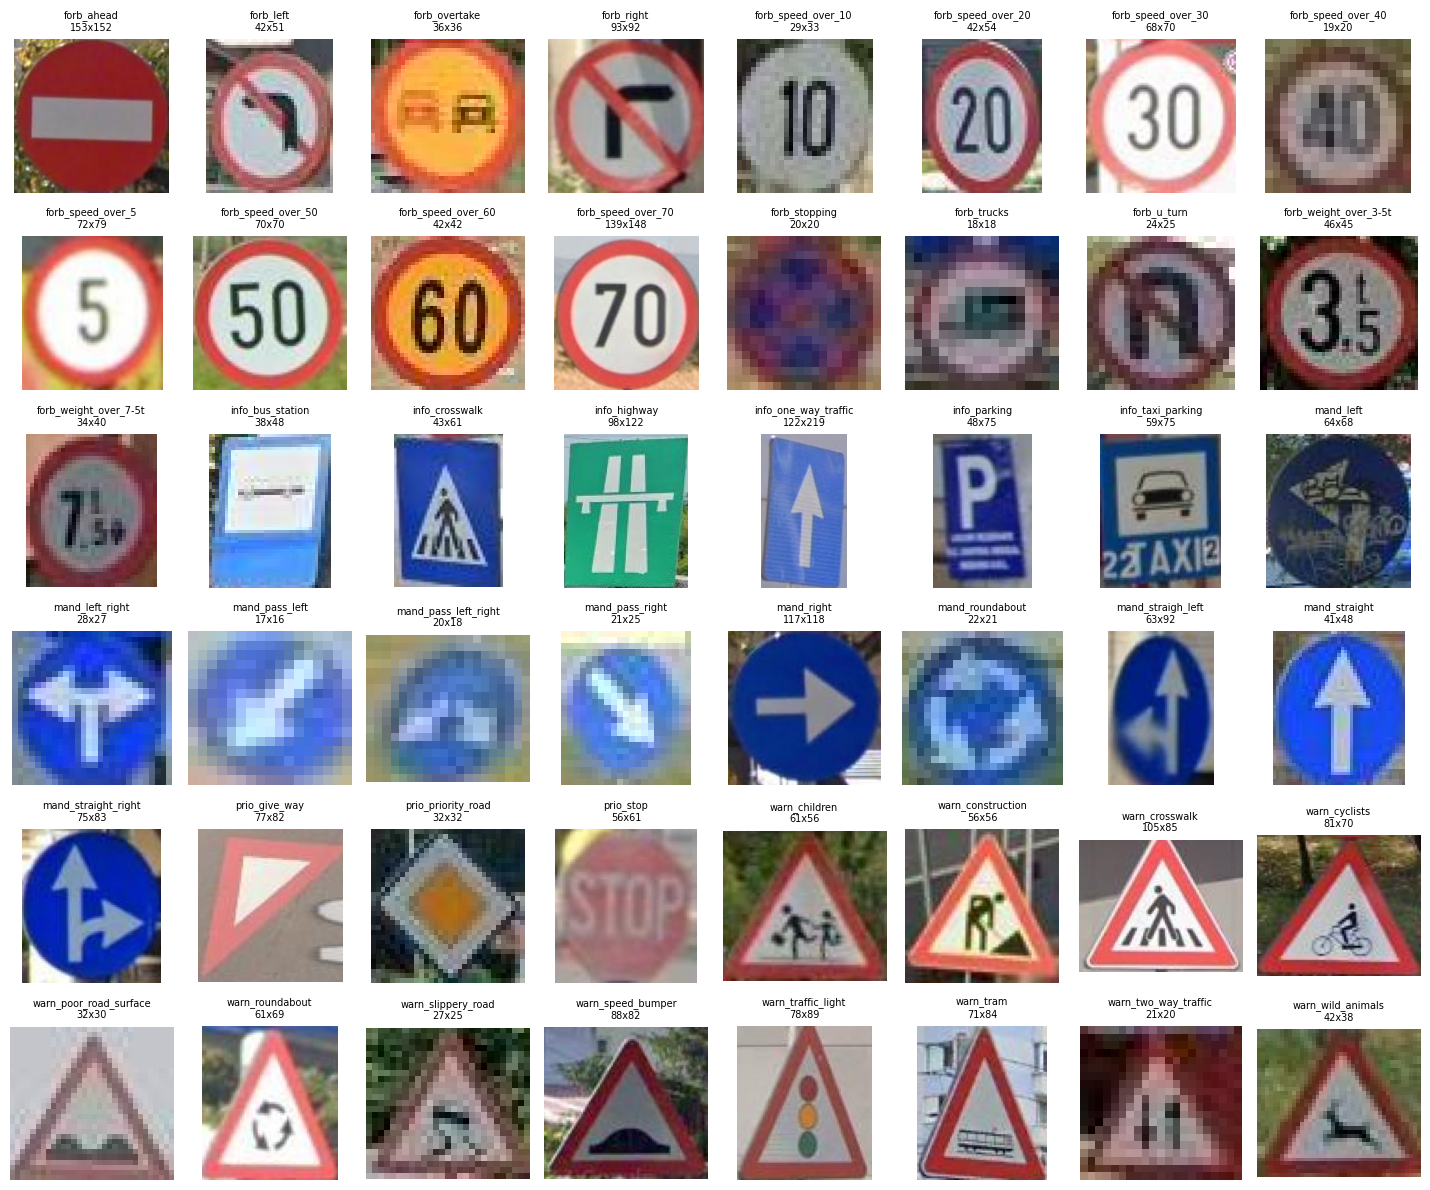

In [12]:
# one training example per class, at its original size (written in the title)
labelNames = sorted(keptClasses)

columns = 8
rows = (len(labelNames) + columns - 1) // columns
figure, axes = plt.subplots(rows, columns, figsize=(columns * 1.8, rows * 2), squeeze=False)

for i in range(rows * columns):
    axis = axes[i // columns][i % columns]
    axis.axis("off")
    if i >= len(labelNames):
        continue

    className = labelNames[i]
    for j in range(len(signClasses["train"])):
        if signClasses["train"][j] == className:
            sign = signImages["train"][j]
            axis.imshow(sign)
            axis.set_title(className + "\n" + str(sign.width) + "x" + str(sign.height), fontsize=7)
            break

plt.tight_layout()
plt.show()

In [13]:
import numpy as np

imageSize = 32

# resize: every sign is stretched to imageSize x imageSize so the networks get inputs of the same shape
# normalisation: pixels go from 0-255 to 0-1
def resizeAndNormalize(images):
    x = []
    for image in images:
        resized = image.resize((imageSize, imageSize))
        x.append(np.array(resized) / 255.0)
    return np.array(x, dtype="float32")

xTrain = resizeAndNormalize(signImages["train"])
xValidation = resizeAndNormalize(signImages["valid"])
xTest = resizeAndNormalize(signImages["test"])

print("train", xTrain.shape)
print("validation", xValidation.shape)
print("test", xTest.shape)
print("pixel values between", xTrain.min(), "and", xTrain.max())

train (4087, 32, 32, 3)
validation (918, 32, 32, 3)
test (940, 32, 32, 3)
pixel values between 0.0 and 1.0


In [14]:
numberOfClasses = len(labelNames)

# each class name becomes a number from 0 to numberOfClasses - 1
classIndex = {}
for i in range(numberOfClasses):
    classIndex[labelNames[i]] = i

# labels stay integers (no one-hot vectors): the models will use sparse_categorical_crossentropy
def encodeLabels(classes):
    y = []
    for className in classes:
        y.append(classIndex[className])
    return np.array(y)

yTrain = encodeLabels(signClasses["train"])
yValidation = encodeLabels(signClasses["valid"])
yTest = encodeLabels(signClasses["test"])

print(numberOfClasses, "classes")
print("example:", signClasses["train"][0], "->", yTrain[0])
print("train", yTrain.shape, "validation", yValidation.shape, "test", yTest.shape)

48 classes
example: warn_crosswalk -> 38
train (4087,) validation (918,) test (940,)


## Partie 2 - Construction d’un modèle de référence

Ce premier réseau, un perceptron multicouche (MLP), sert de **point de comparaison** pour le CNN.

**Architecture :** `Input(32×32×3) → Flatten → Dense(128, ReLU) → Dense(48, softmax)`

- **De l'image à l'entrée :** une image couleur 32 × 32 est un tableau de 32 × 32 × 3 = **3 072 valeurs** (une par pixel et par canal R, V, B). `Flatten` les met bout à bout en un vecteur. La structure 2D est perdue : le réseau ne sait pas quels pixels sont voisins.
- **Poids et biais :** chaque neurone calcule une somme pondérée de ses entrées plus un biais, z = w₁x₁ + … + wₙxₙ + b. Les **poids** indiquent l'importance de chaque entrée, le **biais** décale le résultat. Couche cachée : 3 072 × 128 + 128 = 393 344 paramètres ; couche de sortie : 128 × 48 + 48 = 6 192 ; soit **399 536 paramètres** au total.
- **Propagation avant :** l'image traverse les couches l'une après l'autre jusqu'à la sortie.
- **Fonctions d'activation :** **ReLU** (max(0, z)) dans la couche cachée apporte la non-linéarité ; sans elle, empiler des couches reviendrait à une seule transformation linéaire. **Softmax** en sortie transforme les 48 valeurs en probabilités comprises entre 0 et 1 et de somme 1.
- **Fonction de perte :** l'**entropie croisée** −log(p), où p est la probabilité donnée à la vraie classe. Elle vaut 0 si le réseau est sûr et a raison, et devient très grande s'il donne une faible probabilité à la bonne classe.
- **Rétropropagation :** on calcule la dérivée de la perte par rapport à chaque poids, de la sortie vers l'entrée, avec la règle de dérivation en chaîne.
- **Descente de gradient :** chaque poids est déplacé dans le sens qui fait baisser la perte, w ← w − η · ∂L/∂w (η = taux d'apprentissage), sur des mini-lots de 32 images. Nous utilisons **Adam**, une variante qui adapte le pas de chaque poids.
- **Sortie multiclasse :** 48 neurones avec softmax, un par classe ; la classe prédite est celle de plus grande probabilité.

In [15]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# an empty list means training runs on the CPU (in Colab: Runtime > Change runtime type > GPU)
print("GPU:", tf.config.list_physical_devices("GPU"))

# by default TensorFlow takes all the GPU memory and never gives it back:
# memory growth makes it take only what it needs, so YOLO (PyTorch) can use the GPU in part 8
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

# same results at every run: seeds Python, NumPy and TensorFlow (weight initialisation, shuffling during fit)
# and forces the GPU to always compute in the same order
seed = 42
tf.config.experimental.enable_op_determinism()

epochs = 20
batchSize = 32

keras.utils.set_random_seed(seed)

mlp = keras.Sequential([
    layers.Input((imageSize, imageSize, 3)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(numberOfClasses, activation="softmax"),
])

mlp.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
mlp.summary()

mlpHistory = mlp.fit(xTrain, yTrain, validation_data=(xValidation, yValidation), epochs=epochs, batch_size=batchSize)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 48)             │         6,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 399,536 (1.52 MB)

 Trainable params: 399,536 (1.52 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.4713 - loss: 2.3026 - val_accuracy: 0.6471 - val_loss: 1.5644
Epoch 2/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7262 - loss: 1.2651 - val_accuracy: 0.7168 - val_loss: 1.0964
Epoch 3/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7830 - loss: 0.9058 - val_accuracy: 0.7603 - val_loss: 0.8955
Epoch 4/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8224 - loss: 0.7203 - val_accuracy: 0.7778 - val_loss: 0.7915
Epoch 5/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8510 - loss: 0.6078 - val_accuracy: 0.7941 - val_loss: 0.7185
Epoch 6/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8706 - loss: 0.5296 - val_accuracy: 0.7985 - val_loss: 0.6728
Epoch 7/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8852 - loss: 0.4740 - val_accuracy: 0.8105 - val_loss: 0.6451
Epoch 8/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8938 - loss: 0.4324 - val_accuracy: 0.

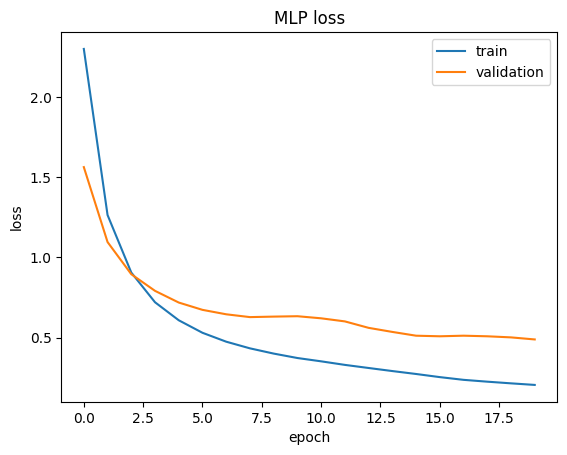

In [16]:
plt.plot(mlpHistory.history["loss"], label="train")
plt.plot(mlpHistory.history["val_loss"], label="validation")
plt.title("MLP loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

MLP test accuracy: 0.878 / test loss: 0.471


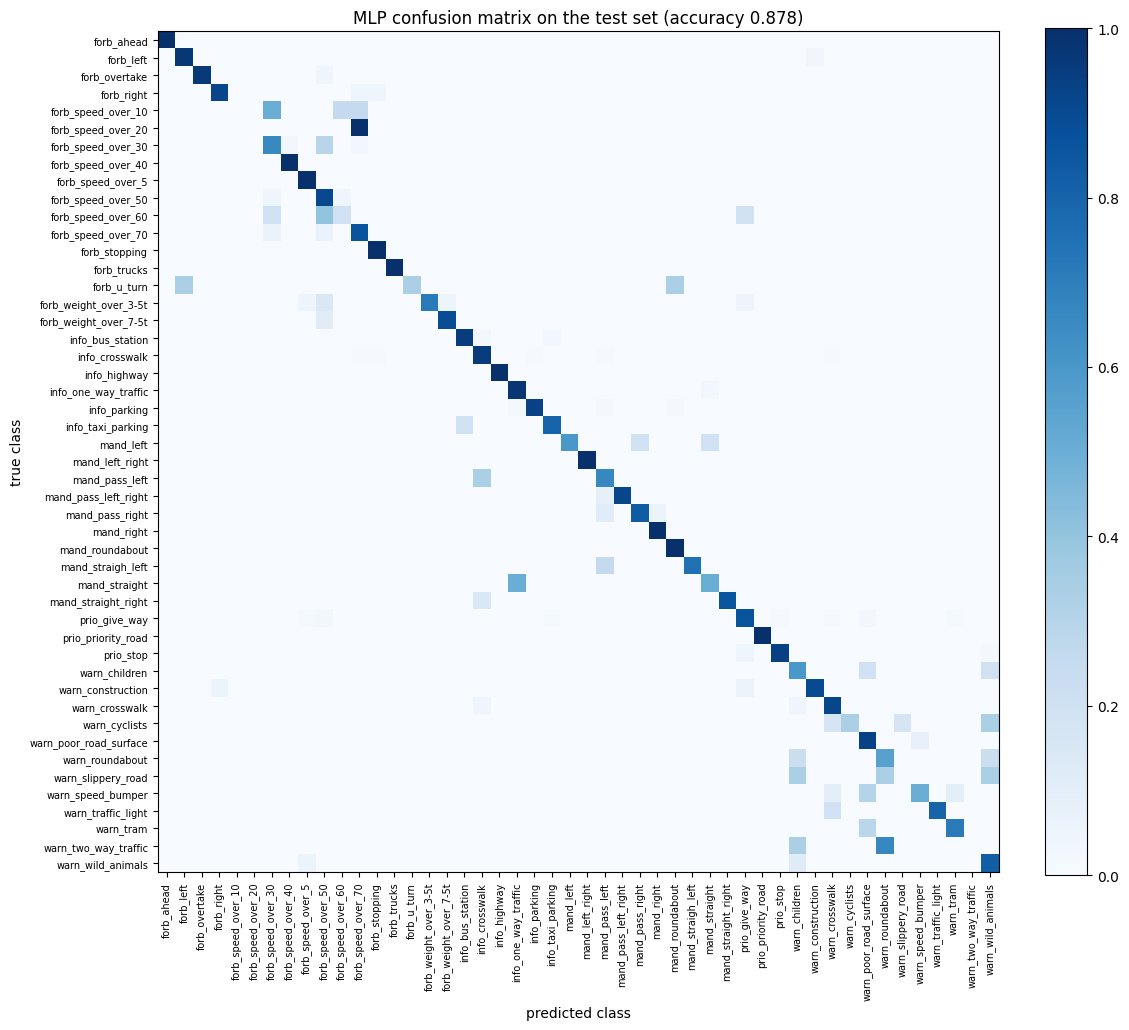

In [17]:
# evaluation on the test set, never used during training
def showTestResults(model, name):
    testLoss, testAccuracy = model.evaluate(xTest, yTest, verbose=0)
    print(name, "test accuracy:", round(testAccuracy, 3), "/ test loss:", round(testLoss, 3))

    predictions = np.argmax(model.predict(xTest, verbose=0), axis=1)

    # rows = true class, columns = predicted class
    matrix = np.zeros((numberOfClasses, numberOfClasses), dtype=int)
    for i in range(len(yTest)):
        matrix[yTest[i]][predictions[i]] += 1

    # each row divided by its total: the colour is the % of the true class, so big classes don't hide the small ones
    rowTotals = matrix.sum(axis=1, keepdims=True)
    percentages = matrix / np.maximum(rowTotals, 1)

    figure, axis = plt.subplots(figsize=(12, 11))
    image = axis.imshow(percentages, cmap="Blues", vmin=0, vmax=1)
    figure.colorbar(image, ax=axis, fraction=0.046)
    axis.set_title(name + " confusion matrix on the test set (accuracy " + str(round(testAccuracy, 3)) + ")")
    axis.set_xlabel("predicted class")
    axis.set_ylabel("true class")
    axis.set_xticks(range(numberOfClasses))
    axis.set_yticks(range(numberOfClasses))
    axis.set_xticklabels(labelNames, rotation=90, fontsize=7)
    axis.set_yticklabels(labelNames, fontsize=7)
    plt.show()

showTestResults(mlp, "MLP")

**Résultat :** le MLP atteint **88,8 % en validation** et **87,8 % en test**, contre 95,4 % sur l'entraînement. C'est un bon point de départ, mais l'écart entre entraînement et validation montre un début de **surapprentissage**, et le MLP doit apprendre chaque motif séparément à chaque position de l'image, faute de connaître la structure 2D.

## Partie 3 - Construction d'un CNN avec Keras

**Architecture :** deux blocs « convolution + ReLU + max pooling » pour **extraire les caractéristiques**, puis `Flatten → Dense → softmax` pour **classer**.

- **Filtres :** petites matrices de poids (ici 3 × 3) apprises pendant l'entraînement. Chaque filtre réagit à un motif : un bord, une couleur, puis, dans les couches suivantes, des formes (cercle, triangle, chiffre, flèche).
- **Convolution sur une image à 3 canaux :** un filtre a la profondeur de son entrée (3 × 3 × 3 pour l'image RGB). Il glisse sur l'image ; à chaque position, on multiplie ses 27 poids par les 27 valeurs couvertes (3 × 3 pixels × 3 canaux), on additionne et on ajoute le biais. Les mêmes poids servent à toutes les positions (**partage des poids**) : un motif est reconnu où qu'il soit.
- **Feature maps :** le résultat d'un filtre sur toute l'image est une carte de caractéristiques. 32 filtres donnent 32 cartes.
- **Taille du kernel (3 × 3) :** petite zone, peu de poids ; deux couches 3 × 3 successives voient déjà une zone plus large de l'image, encore élargie par le pooling.
- **Stride (1) :** le filtre avance d'un pixel à la fois.
- **Padding (« same ») :** on ajoute un bord de zéros pour que la sortie garde la même taille que l'entrée (32 × 32).
- **ReLU :** comme dans le MLP, apporte la non-linéarité.
- **Max pooling (2 × 2) :** garde la plus grande valeur de chaque bloc 2 × 2. Il divise la largeur et la hauteur par 2, réduit le calcul et rend le réseau tolérant aux petits décalages.
- **Flatten :** transforme les 64 cartes de 8 × 8 en un vecteur de 4 096 valeurs.
- **Couche Dense (128) :** combine les caractéristiques extraites pour prendre la décision.
- **Couche de sortie :** 48 neurones avec softmax, comme le MLP.

**Évolution des dimensions et nombre de paramètres :**

| Couche | Sortie | Paramètres | Calcul |
|---|---|---|---|
| Entrée | 32 × 32 × 3 | 0 | |
| Conv2D, 32 filtres 3 × 3 | 32 × 32 × 32 | 896 | 3 × 3 × 3 × 32 + 32 |
| MaxPooling 2 × 2 | 16 × 16 × 32 | 0 | |
| Conv2D, 64 filtres 3 × 3 | 16 × 16 × 64 | 18 496 | 3 × 3 × 32 × 64 + 64 |
| MaxPooling 2 × 2 | 8 × 8 × 64 | 0 | |
| Flatten | 4 096 | 0 | 8 × 8 × 64 |
| Dense 128, ReLU | 128 | 524 416 | 4 096 × 128 + 128 |
| Dense 48, softmax | 48 | 6 192 | 128 × 48 + 48 |
| **Total** | | **550 000** | |

**Justification :** deux blocs suffisent pour des images de 32 × 32 (32 → 16 → 8 ; un troisième bloc réduirait les cartes à 4 × 4). Le nombre de filtres double (32 → 64) quand la taille diminue, pour garder assez d'information. Le réseau reste petit, adapté à environ 4 000 images d'entraînement. Les convolutions n'ont que 19 392 paramètres : 95 % des poids sont dans la première couche Dense.

In [18]:
keras.utils.set_random_seed(seed)

# 2 blocks convolution + ReLU + pooling (feature extraction), then Flatten + Dense (classification)
cnn = keras.Sequential([
    layers.Input((imageSize, imageSize, 3)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(numberOfClasses, activation="softmax"),
])

cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# output shape and number of parameters of each layer
cnn.summary()

cnnHistory = cnn.fit(xTrain, yTrain, validation_data=(xValidation, yValidation), epochs=epochs, batch_size=batchSize)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 48)             │         6,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 550,000 (2.10 MB)

 Trainable params: 550,000 (2.10 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.4727 - loss: 2.2056 - val_accuracy: 0.7342 - val_loss: 1.1377
Epoch 2/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8172 - loss: 0.7447 - val_accuracy: 0.8322 - val_loss: 0.7009
Epoch 3/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8936 - loss: 0.4103 - val_accuracy: 0.8519 - val_loss: 0.5396
Epoch 4/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9369 - loss: 0.2638 - val_accuracy: 0.9063 - val_loss: 0.3822
Epoch 5/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9582 - loss: 0.1862 - val_accuracy: 0.9118 - val_loss: 0.3225
Epoch 6/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9679 - loss: 0.1380 - val_accuracy: 0.9325 - val_loss: 0.2880
Epoch 7/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9768 - loss: 0.1021 - val_accuracy: 0.9281 - val_loss: 0.2948
Epoch 8/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9792 - loss: 0.0850 - val_accuracy: 0.

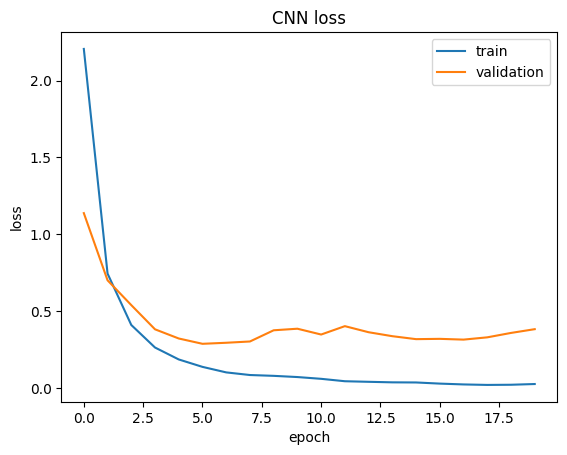

CNN test accuracy: 0.911 / test loss: 0.433


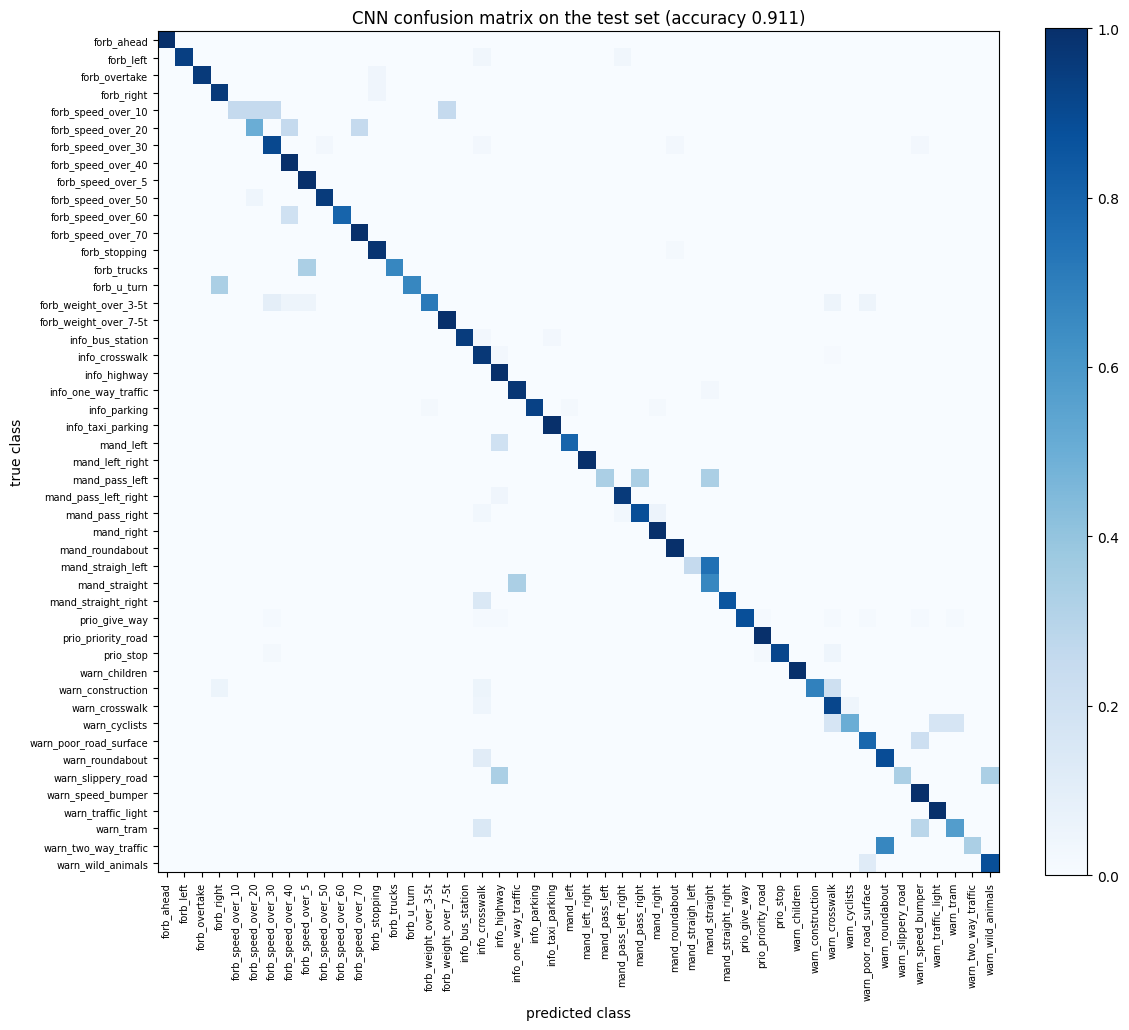

In [19]:
plt.plot(cnnHistory.history["loss"], label="train")
plt.plot(cnnHistory.history["val_loss"], label="validation")
plt.title("CNN loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

showTestResults(cnn, "CNN")

**Résultat :** le CNN atteint **91,1 % en test** (F1 macro 0,82), contre 87,8 % pour le MLP. Grâce au partage des poids et au pooling, il reconnaît un motif où qu'il soit dans l'image, ce que le MLP ne sait pas faire.

## Partie 4 - Entraînement du réseau

**Choix d'entraînement :**
- **Fonction de perte : `sparse_categorical_crossentropy`.** C'est l'entropie croisée pour un problème multiclasse avec une sortie softmax ; la version *sparse* accepte directement les labels entiers.
- **Optimiseur : Adam, taux d'apprentissage 0,001.** C'est la valeur par défaut, robuste. La partie 6 le confirme : 0,01 est trop grand (93,2 % → 89,3 % en validation), 0,0001 est trop lent (38 époques pour 90,6 %).
- **Batch size : 32.** C'est un compromis : les poids sont mis à jour 128 fois par époque, avec un gradient assez stable.
- **Nombre d'époques : 20** pour le MLP et le CNN de référence. La partie 6 utilise l'*early stopping*, qui montre que la meilleure époque arrive bien plus tôt (vers la 6ᵉ–8ᵉ).
- **Métriques :** l'**accuracy** pour suivre l'entraînement, et le **F1 macro** pour comparer les modèles, car avec des classes déséquilibrées l'accuracy reflète surtout les grandes classes.

**Lecture des courbes :** les pointillés sont l'entraînement, les traits pleins la validation. Pour le CNN, la loss d'entraînement descend jusqu'à 0,03 (accuracy 99,6 %) alors que la loss de validation cesse de baisser après quelques époques et reste vers 0,38 (accuracy 92,8 %). Le réseau continue d'apprendre les images d'entraînement par cœur sans mieux généraliser : c'est du **surapprentissage**. Le MLP montre le même phénomène, moins marqué (95,4 % contre 88,8 %). La partie 6 le traite avec le **dropout** et l'**early stopping**.

## Partie 5 - Évaluation et analyse des erreurs

Cette partie analyse le **CNN de la partie 3**. Le modèle final, choisi dans la partie 6, est évalué sur le test dans la partie 6.3.

In [20]:
# the model analysed here (to replace by the final model after part 6)
finalModel = cnn

testProbabilities = finalModel.predict(xTest, verbose=0)
testPredictions = np.argmax(testProbabilities, axis=1)

# per class: precision = of the signs predicted as this class, % that really are
#            recall    = of the signs of this class, % predicted as this class
#            F1        = harmonic mean of precision and recall
precisionOfClass = {}
recallOfClass = {}
f1OfClass = {}
supportOfClass = {}
for classNumber in range(numberOfClasses):
    truePositives = 0
    falsePositives = 0
    falseNegatives = 0
    for i in range(len(yTest)):
        if testPredictions[i] == classNumber and yTest[i] == classNumber:
            truePositives += 1
        elif testPredictions[i] == classNumber:
            falsePositives += 1
        elif yTest[i] == classNumber:
            falseNegatives += 1

    precision = truePositives / max(truePositives + falsePositives, 1)
    recall = truePositives / max(truePositives + falseNegatives, 1)
    precisionOfClass[classNumber] = precision
    recallOfClass[classNumber] = recall
    f1OfClass[classNumber] = 2 * precision * recall / max(precision + recall, 1e-9)
    supportOfClass[classNumber] = truePositives + falseNegatives

# from the worst class (lowest F1) to the best
print("class".ljust(26), "precision".rjust(9), "recall".rjust(7), "F1".rjust(5), "support".rjust(8))
for classNumber in sorted(range(numberOfClasses), key=f1OfClass.get):
    print(labelNames[classNumber].ljust(26),
          str(round(precisionOfClass[classNumber], 2)).rjust(9),
          str(round(recallOfClass[classNumber], 2)).rjust(7),
          str(round(f1OfClass[classNumber], 2)).rjust(5),
          str(supportOfClass[classNumber]).rjust(8))

# macro average: every class counts the same, so small classes weigh as much as big ones
correct = 0
for i in range(len(yTest)):
    if testPredictions[i] == yTest[i]:
        correct += 1
print("\naccuracy:", round(correct / len(yTest), 3))
print("macro precision:", round(sum(precisionOfClass.values()) / numberOfClasses, 3))
print("macro recall:", round(sum(recallOfClass.values()) / numberOfClasses, 3))
print("macro F1:", round(sum(f1OfClass.values()) / numberOfClasses, 3))

# most frequent confusions
confusions = {}
for i in range(len(yTest)):
    if testPredictions[i] != yTest[i]:
        pair = (labelNames[yTest[i]], labelNames[testPredictions[i]])
        confusions[pair] = confusions.get(pair, 0) + 1

print("\nmost frequent confusions (count, true class -> predicted class):")
for pair in sorted(confusions, key=confusions.get, reverse=True)[:15]:
    print("  ", confusions[pair], pair[0], "->", pair[1])

class                      precision  recall    F1  support
info_highway                    0.22     1.0  0.36        2
forb_speed_over_10               1.0    0.25   0.4        4
mand_straigh_left                1.0    0.25   0.4        4
forb_speed_over_20               0.5     0.5   0.5        4
mand_pass_left                   1.0    0.33   0.5        3
warn_slippery_road               1.0    0.33   0.5        3
warn_two_way_traffic             1.0    0.33   0.5        3
mand_straight                   0.44    0.67  0.53        6
warn_cyclists                   0.75     0.5   0.6        6
warn_tram                       0.67    0.57  0.62        7
warn_speed_bumper               0.59     1.0  0.74       10
warn_poor_road_surface          0.73    0.79  0.76       14
warn_crosswalk                  0.68    0.91  0.78       23
forb_trucks                      1.0    0.67   0.8        3
forb_u_turn                      1.0    0.67   0.8        3
mand_left                        0.8    

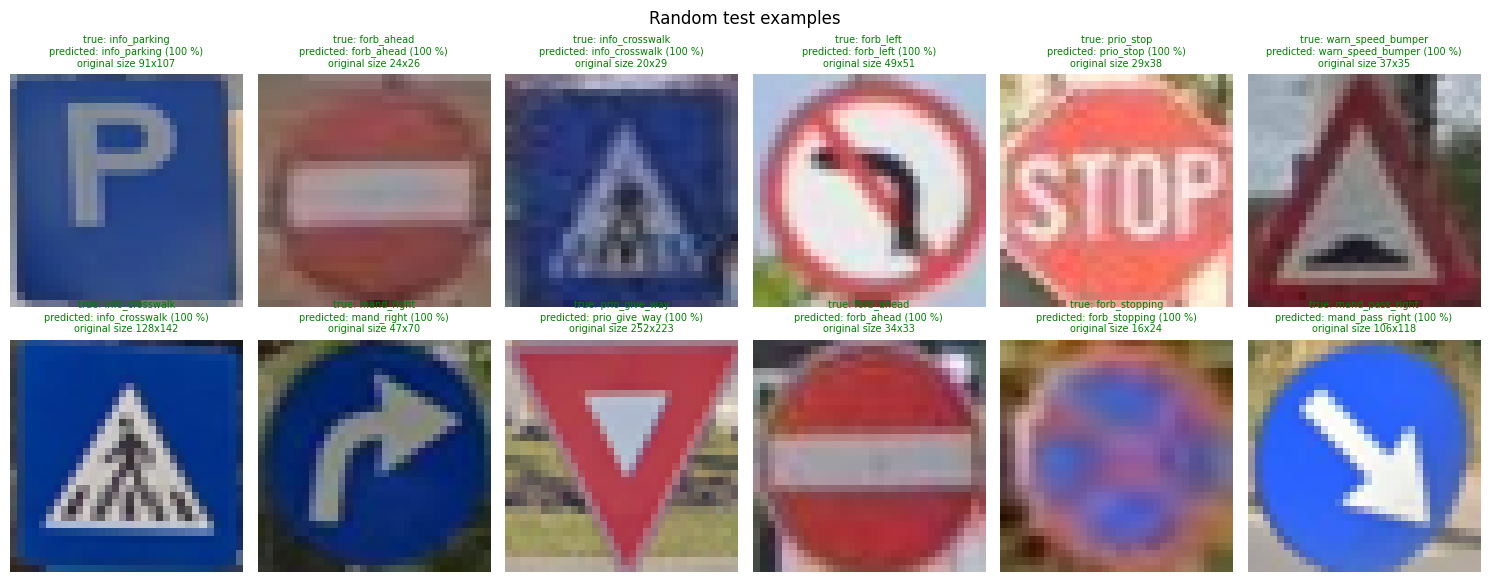

84 wrong predictions out of 940


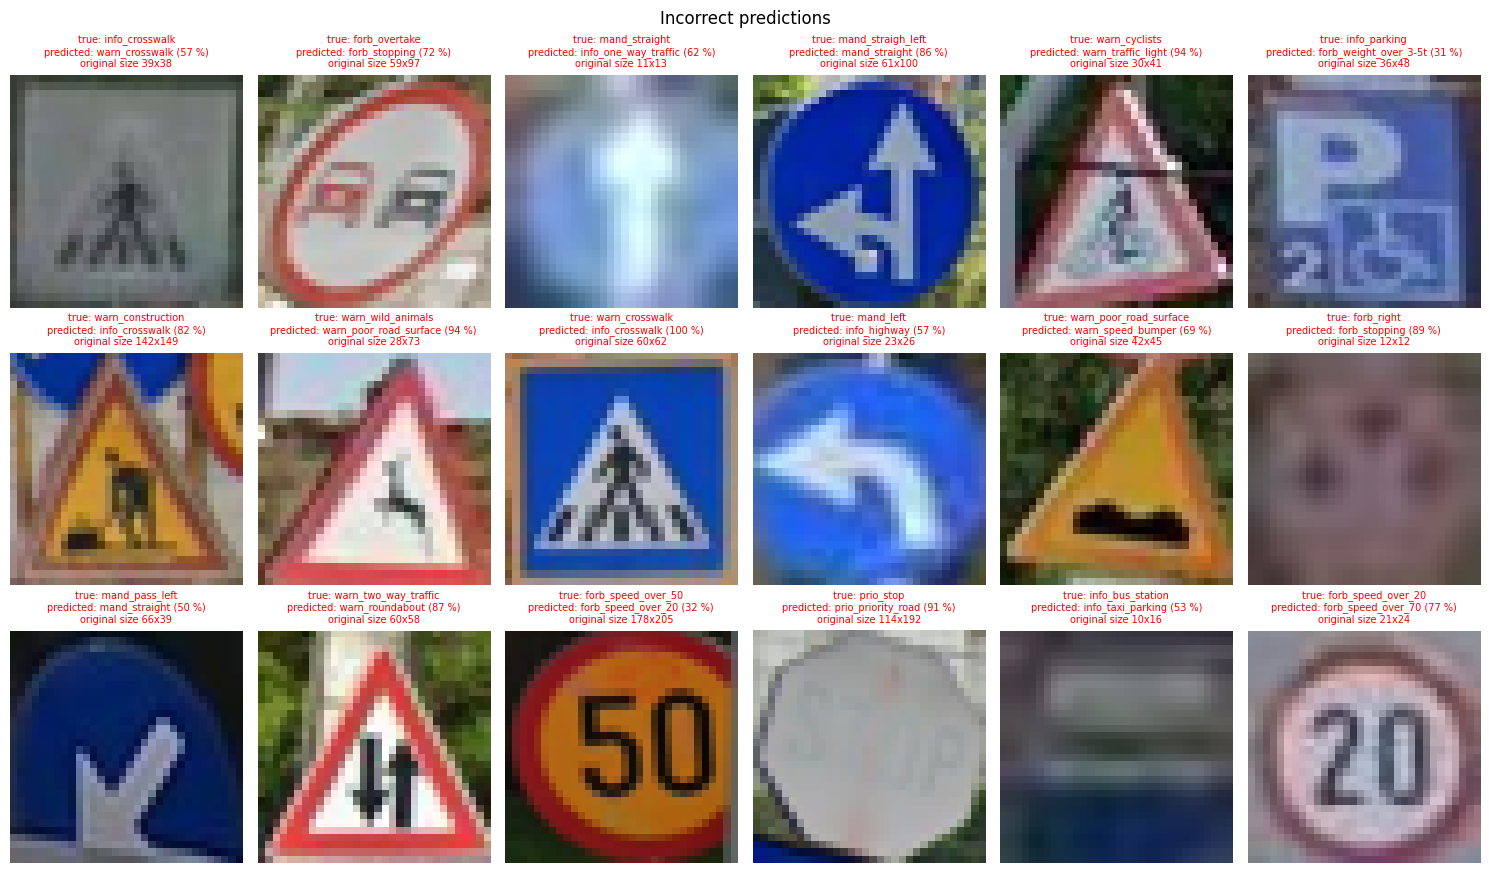

In [21]:
# image (as the model sees it, 32x32) + true class + predicted class + probability
# green = correct, red = wrong; the original size of the sign is written below
def showExamples(indices, title):
    columns = 6
    rows = (len(indices) + columns - 1) // columns
    figure, axes = plt.subplots(rows, columns, figsize=(columns * 2.5, rows * 3), squeeze=False)

    for k in range(rows * columns):
        axis = axes[k // columns][k % columns]
        axis.axis("off")
        if k >= len(indices):
            continue

        i = indices[k]
        predicted = testPredictions[i]
        probability = round(100 * testProbabilities[i][predicted])
        original = signImages["test"][i]

        axis.imshow(xTest[i])
        if predicted == yTest[i]:
            color = "green"
        else:
            color = "red"
        axis.set_title("true: " + labelNames[yTest[i]] + "\npredicted: " + labelNames[predicted] + " (" + str(probability) + " %)\noriginal size " + str(original.width) + "x" + str(original.height), fontsize=7, color=color)

    figure.suptitle(title)
    plt.tight_layout()
    plt.show()

random.seed(seed)
showExamples(random.sample(range(len(yTest)), 12), "Random test examples")

wrongIndices = []
for i in range(len(yTest)):
    if testPredictions[i] != yTest[i]:
        wrongIndices.append(i)

print(len(wrongIndices), "wrong predictions out of", len(yTest))
showExamples(random.sample(wrongIndices, min(18, len(wrongIndices))), "Incorrect predictions")

In [22]:
# are errors linked to the size of the sign or to the light? accuracy per group of test signs
def accuracyOfGroup(indices):
    correct = 0
    for i in indices:
        if testPredictions[i] == yTest[i]:
            correct += 1
    return round(100 * correct / max(len(indices), 1))

# size = smallest side of the original box, in pixels
sizeGroups = {"small (< 30 px)": [], "medium (30-60 px)": [], "large (>= 60 px)": []}
for i in range(len(yTest)):
    side = min(signImages["test"][i].width, signImages["test"][i].height)
    if side < 30:
        sizeGroups["small (< 30 px)"].append(i)
    elif side < 60:
        sizeGroups["medium (30-60 px)"].append(i)
    else:
        sizeGroups["large (>= 60 px)"].append(i)

# brightness = mean pixel value of the sign, between 0 (black) and 1 (white)
lightGroups = {"dark (< 0.3)": [], "normal (0.3-0.6)": [], "bright (>= 0.6)": []}
for i in range(len(yTest)):
    brightness = xTest[i].mean()
    if brightness < 0.3:
        lightGroups["dark (< 0.3)"].append(i)
    elif brightness < 0.6:
        lightGroups["normal (0.3-0.6)"].append(i)
    else:
        lightGroups["bright (>= 0.6)"].append(i)

print("by size:")
for group in sizeGroups:
    print("   ", group.ljust(20), len(sizeGroups[group]), "signs, accuracy", accuracyOfGroup(sizeGroups[group]), "%")

print("by brightness:")
for group in lightGroups:
    print("   ", group.ljust(20), len(lightGroups[group]), "signs, accuracy", accuracyOfGroup(lightGroups[group]), "%")

by size:
    small (< 30 px)      236 signs, accuracy 86 %
    medium (30-60 px)    354 signs, accuracy 93 %
    large (>= 60 px)     350 signs, accuracy 93 %
by brightness:
    dark (< 0.3)         109 signs, accuracy 90 %
    normal (0.3-0.6)     715 signs, accuracy 91 %
    bright (>= 0.6)      116 signs, accuracy 92 %


#### Analyse

- **Performances globales :** accuracy de 91,1 % mais **F1 macro de 0,82**. Les grandes classes, très distinctes, sont presque parfaites (`forb_ahead`, `forb_overtake`, `forb_stopping`, `info_bus_station`, `prio_stop` : F1 ≥ 0,95). Les erreurs se concentrent sur des classes rares.
- **Classes les plus difficiles :** `info_highway`, `forb_speed_over_10`, `mand_straigh_left`, `forb_speed_over_20`, `mand_pass_left`, `warn_slippery_road`, `warn_two_way_traffic` (F1 entre 0,36 et 0,5). Ce sont toutes des classes avec **peu d'exemples** (12 à 20 en entraînement, 2 à 4 en test). Avec si peu d'exemples de test, un seul panneau mal classé fait varier le F1 de 0,2 à 0,3 : ces scores sont donc peu fiables.
- **Panneaux fréquemment confondus,** presque toujours des panneaux de même forme et de même couleur qui ne diffèrent que par un petit détail :
  - **pictogrammes de danger** (triangle rouge) : `warn_construction` → `warn_crosswalk`, `warn_poor_road_surface` → `warn_speed_bumper` (deux pictogrammes de bosses sur la route), `warn_tram` → `warn_speed_bumper` ;
  - **flèches** (cercle ou carré bleu) : `mand_straigh_left` → `mand_straight`, `mand_straight` → `info_one_way_traffic` (flèche blanche sur fond bleu dans les deux cas), `mand_pass_right` → `mand_right` ;
  - **cercles rouges avec un chiffre** : `forb_weight_over_3-5t` → `forb_speed_over_30`, et les limitations de vitesse entre elles.

  À 32 × 32 pixels, un chiffre ou une flèche n'occupe que quelques pixels : c'est la **ressemblance entre classes** combinée à la faible résolution.
- **Taille du panneau :** les petits panneaux (moins de 30 px) sont nettement moins bien reconnus (**86 %**) que les moyens et les grands (**93 %**). Agrandis à 32 × 32, ils sont flous.
- **Luminosité :** peu d'effet (90 % pour les panneaux sombres, 91 % normaux, 92 % clairs). Le réseau est robuste à l'éclairage de ce jeu de données.
- **Angle de vue et flou :** visibles dans la grille des erreurs : panneaux vus de biais, partiellement cachés, ou très petits et pixelisés.

## Partie 6 - Expérimentation et amélioration

In [23]:
# all the experiments are compared on the VALIDATION set; the test set is used only once, for the final model
maxEpochs = 40

# the CNN of part 3, with the settings we want to explore
baseConfig = {
    "learningRate": 0.001,
    "batchSize": 32,
    "filters": 32,       # filters of the first convolution (the second has twice as many)
    "kernelSize": 3,
    "dense": 128,        # neurons of the hidden dense layer
    "dropout": 0.0,
    "imageSize": 32,
}

def buildCnn(config, augmentation=False):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential()
    model.add(layers.Input((config["imageSize"], config["imageSize"], 3)))
    if augmentation:
        model.add(makeAugmentation())
    model.add(layers.Conv2D(config["filters"], config["kernelSize"], padding="same", activation="relu"))
    model.add(layers.MaxPooling2D(2))
    model.add(layers.Conv2D(2 * config["filters"], config["kernelSize"], padding="same", activation="relu"))
    model.add(layers.MaxPooling2D(2))
    model.add(layers.Flatten())
    if config["dropout"] > 0:
        model.add(layers.Dropout(config["dropout"]))
    model.add(layers.Dense(config["dense"], activation="relu"))
    if config["dropout"] > 0:
        model.add(layers.Dropout(config["dropout"]))
    model.add(layers.Dense(numberOfClasses, activation="softmax"))
    return model

# the MLP of part 2
def buildMlp(config, augmentation=False):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential()
    model.add(layers.Input((config["imageSize"], config["imageSize"], 3)))
    if augmentation:
        model.add(makeAugmentation())
    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation="relu"))
    model.add(layers.Dense(numberOfClasses, activation="softmax"))
    return model

# the same signs resized to another size (the labels do not change)
def resizeTo(images, size):
    x = []
    for image in images:
        x.append(np.array(image.resize((size, size))) / 255.0)
    return np.array(x, dtype="float32")

inputsOfSize = {32: (xTrain, xValidation)}

# accuracy and macro F1 (mean of the F1 of every class, so the small classes count as much as the big ones)
def scores(model, x, y):
    predictions = np.argmax(model.predict(x, verbose=0), axis=1)
    accuracy = np.mean(predictions == y)
    f1Total = 0
    for classNumber in range(numberOfClasses):
        truePositives = np.sum((predictions == classNumber) & (y == classNumber))
        falsePositives = np.sum((predictions == classNumber) & (y != classNumber))
        falseNegatives = np.sum((predictions != classNumber) & (y == classNumber))
        precision = truePositives / max(truePositives + falsePositives, 1)
        recall = truePositives / max(truePositives + falseNegatives, 1)
        f1Total += 2 * precision * recall / max(precision + recall, 1e-9)
    return accuracy, f1Total / numberOfClasses

# early stopping: training stops when the validation loss has not improved for 5 epochs,
# and the weights of the best epoch are kept
results = []
def runExperiment(name, kind, model, config):
    size = config["imageSize"]
    if size not in inputsOfSize:
        inputsOfSize[size] = (resizeTo(signImages["train"], size), resizeTo(signImages["valid"], size))
    xTrainRun, xValidationRun = inputsOfSize[size]

    model.compile(optimizer=keras.optimizers.Adam(config["learningRate"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    history = model.fit(xTrainRun, yTrain, validation_data=(xValidationRun, yValidation), epochs=maxEpochs, batch_size=config["batchSize"], callbacks=[stopping], verbose=0)

    trainAccuracy, trainF1 = scores(model, xTrainRun, yTrain)
    validationAccuracy, validationF1 = scores(model, xValidationRun, yValidation)
    results.append({
        "name": name, "kind": kind, "config": dict(config), "model": model, "history": history,
        "epochs": len(history.history["loss"]), "trainAccuracy": trainAccuracy,
        "validationAccuracy": validationAccuracy, "validationF1": validationF1,
    })
    print(name.ljust(32), "val accuracy", round(validationAccuracy, 3), "| val macro F1", round(validationF1, 3), "| train accuracy", round(trainAccuracy, 3), "|", len(history.history["loss"]), "epochs")
    return validationF1

def showResults(rows):
    print("experiment".ljust(32), "val acc".rjust(8), "val F1".rjust(7), "train acc".rjust(10), "gap".rjust(6), "epochs".rjust(7))
    for row in rows:
        gap = row["trainAccuracy"] - row["validationAccuracy"]
        print(row["name"].ljust(32), str(round(row["validationAccuracy"], 3)).rjust(8), str(round(row["validationF1"], 3)).rjust(7),
              str(round(row["trainAccuracy"], 3)).rjust(10), str(round(gap, 3)).rjust(6), str(row["epochs"]).rjust(7))

### 6.1 Exploration des hyperparamètres

On part du CNN de la partie 3 et on change **un seul hyperparamètre à la fois**, pour pouvoir attribuer l'effet observé à ce changement.

In [24]:
# baseline, then one hyperparameter changed at a time
baselineF1 = runExperiment("CNN baseline", "cnn", buildCnn(baseConfig), baseConfig)

explorations = [
    ("learningRate", [0.0001, 0.01]),
    ("batchSize", [16, 64]),
    ("filters", [16, 64]),
    ("kernelSize", [5]),
    ("dense", [64, 256]),
    ("dropout", [0.3, 0.5]),
    ("imageSize", [48]),
]

scoreOf = {}
for parameter, values in explorations:
    for value in values:
        config = dict(baseConfig)
        config[parameter] = value
        scoreOf[(parameter, value)] = runExperiment("CNN " + parameter + " = " + str(value), "cnn", buildCnn(config), config)

CNN baseline                     val accuracy 0.932 | val macro F1 0.856 | train accuracy 0.973 | 11 epochs
CNN learningRate = 0.0001        val accuracy 0.906 | val macro F1 0.802 | train accuracy 0.972 | 38 epochs
CNN learningRate = 0.01          val accuracy 0.893 | val macro F1 0.783 | train accuracy 0.948 | 11 epochs
CNN batchSize = 16               val accuracy 0.93 | val macro F1 0.868 | train accuracy 0.984 | 13 epochs
CNN batchSize = 64               val accuracy 0.914 | val macro F1 0.817 | train accuracy 0.961 | 11 epochs
CNN filters = 16                 val accuracy 0.938 | val macro F1 0.877 | train accuracy 0.969 | 12 epochs
CNN filters = 64                 val accuracy 0.928 | val macro F1 0.863 | train accuracy 0.975 | 11 epochs
CNN kernelSize = 5               val accuracy 0.931 | val macro F1 0.852 | train accuracy 0.981 | 14 epochs
CNN dense = 64                   val accuracy 0.926 | val macro F1 0.825 | train accuracy 0.965 | 12 epochs
CNN dense = 256              

In [25]:
# for each hyperparameter, we keep the value with the best validation macro F1 (the baseline value if nothing is better)
bestConfig = dict(baseConfig)
for parameter, values in explorations:
    bestScore = baselineF1
    for value in values:
        if scoreOf[(parameter, value)] > bestScore:
            bestScore = scoreOf[(parameter, value)]
            bestConfig[parameter] = value

print("best value of each hyperparameter:", bestConfig)

# the best values are combined in one model (their effects are not always additive, so we check it)
runExperiment("CNN best hyperparameters", "cnn", buildCnn(bestConfig), bestConfig)
print()
showResults(results)

best value of each hyperparameter: {'learningRate': 0.001, 'batchSize': 16, 'filters': 16, 'kernelSize': 3, 'dense': 256, 'dropout': 0.3, 'imageSize': 48}
CNN best hyperparameters         val accuracy 0.943 | val macro F1 0.902 | train accuracy 0.982 | 12 epochs

experiment                        val acc  val F1  train acc    gap  epochs
CNN baseline                        0.932   0.856      0.973  0.041      11
CNN learningRate = 0.0001           0.906   0.802      0.972  0.066      38
CNN learningRate = 0.01             0.893   0.783      0.948  0.055      11
CNN batchSize = 16                   0.93   0.868      0.984  0.054      13
CNN batchSize = 64                  0.914   0.817      0.961  0.047      11
CNN filters = 16                    0.938   0.877      0.969  0.031      12
CNN filters = 64                    0.928   0.863      0.975  0.047      11
CNN kernelSize = 5                  0.931   0.852      0.981   0.05      14
CNN dense = 64                      0.926   0.825   

### 6.2 Data augmentation

Chaque image d'entraînement est légèrement modifiée à chaque époque : petite rotation, zoom, décalage, luminosité et contraste. **Pas de retournement horizontal** : il transformerait `mand_left` en `mand_right` (ou `mand_pass_left` en `mand_pass_right`) sans changer le label. Les couches d'augmentation ne sont actives que pendant l'entraînement : la validation et le test voient les images d'origine.

In [26]:
def makeAugmentation():
    return keras.Sequential([
        layers.RandomRotation(0.03),                    # about +-10 degrees
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomBrightness(0.2, value_range=(0, 1)),
        layers.RandomContrast(0.2),
    ])

# MLP and CNN, without and with augmentation, trained the same way
mlpConfig = dict(baseConfig)
runExperiment("MLP", "mlp", buildMlp(mlpConfig), mlpConfig)
runExperiment("MLP + augmentation", "mlp", buildMlp(mlpConfig, augmentation=True), mlpConfig)
runExperiment("CNN best hyperparameters + augm.", "cnn", buildCnn(bestConfig, augmentation=True), bestConfig)

print()
showResults(results)

MLP                              val accuracy 0.893 | val macro F1 0.782 | train accuracy 0.955 | 27 epochs
MLP + augmentation               val accuracy 0.82 | val macro F1 0.652 | train accuracy 0.858 | 33 epochs
CNN best hyperparameters + augm. val accuracy 0.947 | val macro F1 0.867 | train accuracy 0.972 | 19 epochs

experiment                        val acc  val F1  train acc    gap  epochs
CNN baseline                        0.932   0.856      0.973  0.041      11
CNN learningRate = 0.0001           0.906   0.802      0.972  0.066      38
CNN learningRate = 0.01             0.893   0.783      0.948  0.055      11
CNN batchSize = 16                   0.93   0.868      0.984  0.054      13
CNN batchSize = 64                  0.914   0.817      0.961  0.047      11
CNN filters = 16                    0.938   0.877      0.969  0.031      12
CNN filters = 64                    0.928   0.863      0.975  0.047      11
CNN kernelSize = 5                  0.931   0.852      0.981   0.05 

### 6.3 Choix du modèle final

final model: CNN dropout = 0.3 {'learningRate': 0.001, 'batchSize': 32, 'filters': 32, 'kernelSize': 3, 'dense': 128, 'dropout': 0.3, 'imageSize': 32}


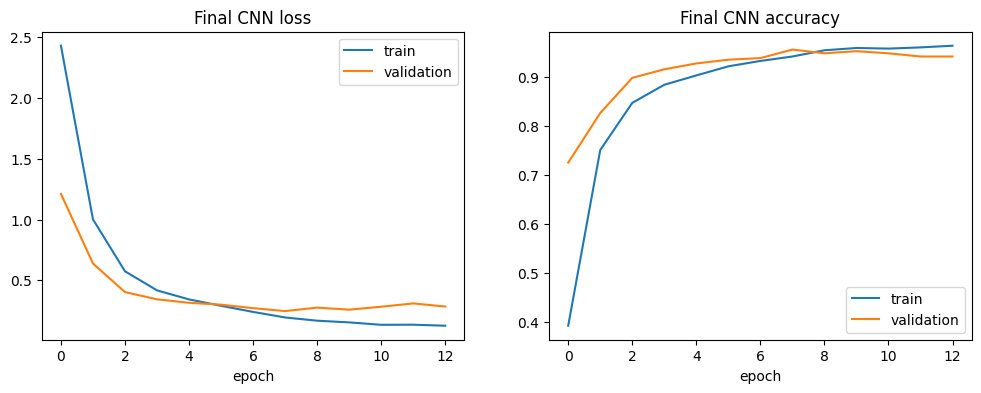

Final CNN test accuracy: 0.933 / test loss: 0.277


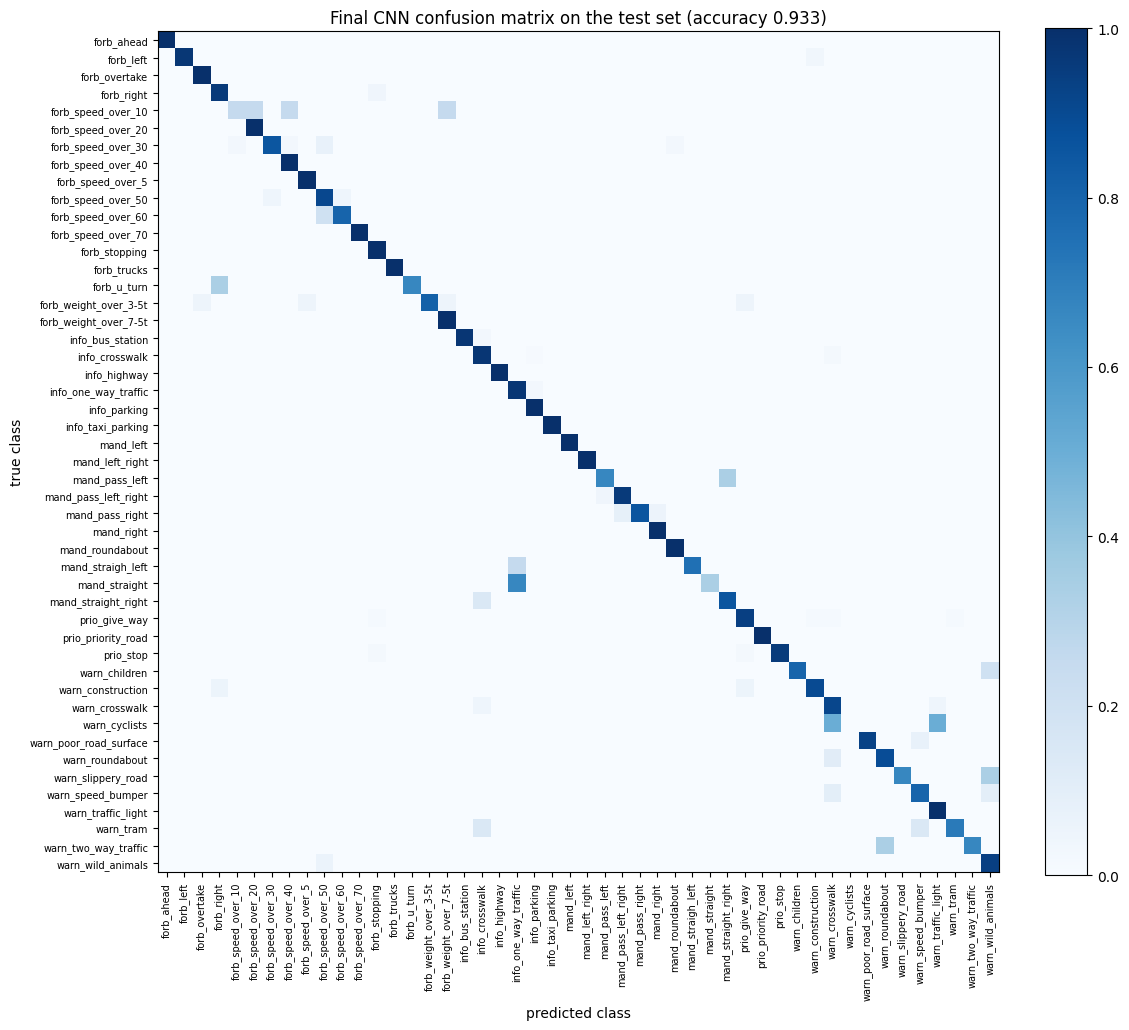

In [27]:
# final model = the CNN with the best validation macro F1
finalRow = None
for row in results:
    if row["kind"] == "cnn" and (finalRow is None or row["validationF1"] > finalRow["validationF1"]):
        finalRow = row

print("final model:", finalRow["name"], finalRow["config"])
finalModel = finalRow["model"]

# from now on, the data are prepared at the size of the final model (also used by the YOLO pipeline in part 8)
imageSize = finalRow["config"]["imageSize"]
xTrain = resizeTo(signImages["train"], imageSize)
xValidation = resizeTo(signImages["valid"], imageSize)
xTest = resizeTo(signImages["test"], imageSize)

history = finalRow["history"].history
figure, (lossPlot, accuracyPlot) = plt.subplots(1, 2, figsize=(12, 4))
lossPlot.plot(history["loss"], label="train")
lossPlot.plot(history["val_loss"], label="validation")
lossPlot.set_title("Final CNN loss")
lossPlot.set_xlabel("epoch")
lossPlot.legend()
accuracyPlot.plot(history["accuracy"], label="train")
accuracyPlot.plot(history["val_accuracy"], label="validation")
accuracyPlot.set_title("Final CNN accuracy")
accuracyPlot.set_xlabel("epoch")
accuracyPlot.legend()
plt.show()

# the only evaluation on the test set
showTestResults(finalModel, "Final CNN")

#### Comparaison des expériences (validation)

| Expérience | Val. accuracy | Val. F1 macro | Écart train − val | Observation |
|---|---|---|---|---|
| CNN de référence | 0,932 | 0,856 | 0,041 | point de départ |
| learning rate 0,0001 | 0,906 | 0,802 | 0,066 | trop lent : 38 époques pour un moins bon résultat |
| learning rate 0,01 | 0,893 | 0,783 | 0,055 | pas trop grand, l'optimisation est instable |
| batch size 16 | 0,930 | 0,868 | 0,054 | léger gain en F1 (mises à jour plus fréquentes) |
| batch size 64 | 0,914 | 0,817 | 0,047 | moins bon |
| 16 filtres | 0,938 | 0,877 | 0,031 | mieux avec moins de paramètres : moins de surapprentissage |
| 64 filtres | 0,928 | 0,863 | 0,047 | plus de capacité, pas de gain |
| kernel 5 × 5 | 0,931 | 0,852 | 0,050 | pas de gain : les détails utiles sont petits |
| Dense 64 | 0,926 | 0,825 | 0,039 | pas assez de neurones pour 48 classes |
| Dense 256 | 0,920 | 0,865 | 0,055 | léger gain en F1, plus de surapprentissage |
| **dropout 0,3** | **0,956** | **0,914** | **0,025** | **meilleur résultat et plus petit écart : la régularisation réduit le surapprentissage** |
| dropout 0,5 | 0,956 | 0,911 | 0,035 | aussi bon, mais deux fois plus d'époques |
| images 48 × 48 | 0,926 | 0,874 | 0,046 | F1 meilleur (plus de détails pour les chiffres et les flèches), accuracy plus basse |
| meilleures valeurs combinées | 0,943 | 0,902 | 0,039 | moins bon que le dropout seul : les effets ne s'additionnent pas |
| MLP | 0,893 | 0,782 | 0,062 | référence |
| MLP + augmentation | 0,820 | 0,652 | 0,038 | nettement pire |
| CNN combiné + augmentation | 0,947 | 0,867 | 0,025 | écart réduit, mais F1 plus bas |

**Observations :**
- La **régularisation** est le levier le plus efficace : le dropout 0,3 fait passer le F1 macro de 0,856 à 0,914, car il empêche le réseau de dépendre de quelques neurones et réduit le surapprentissage.
- Le **taux d'apprentissage** par défaut (0,001) est le bon : 10 fois plus grand ou plus petit dégrade le résultat.
- **Combiner les meilleures valeurs** ne donne pas le meilleur modèle : les hyperparamètres interagissent, et changer un paramètre à la fois ne mesure que son effet isolé.
- La **data augmentation** dégrade fortement le MLP : un panneau décalé ou tourné de quelques pixels devient pour lui une entrée complètement différente, car il n'a aucune invariance spatiale. Le CNN, grâce à la convolution et au pooling, la supporte bien (écart train − val réduit à 0,025), mais son F1 baisse. Hypothèse : sur des panneaux de 32 × 32 pixels, un décalage de 10 % et des rotations déforment trop les petits détails (chiffres, flèches), et l'early stopping arrête l'entraînement avant que le modèle n'en profite.

**Modèle final : CNN de référence + dropout 0,3** (choisi sur le F1 macro de validation). Sur le test, il atteint **93,3 %** d'accuracy et un **F1 macro de 0,87**, contre 91,1 % et 0,82 pour le CNN de la partie 3. C'est ce modèle qu'utilisent le pipeline YOLO et le dashboard.

## Partie 7 - Enrichissement avec les notions du cours

Les notions de la fin du module que nous avons intégrées :
- **Data augmentation** (partie 6.2), avec des transformations qui conservent le sens du panneau (pas de retournement horizontal).
- **Régularisation :** dropout et early stopping (partie 6).
- **Transfer learning :** YOLOv8 nano est pré-entraîné sur COCO (118 000 images) puis *fine-tuné* sur nos panneaux (partie 8). Il réutilise des caractéristiques déjà apprises (bords, formes, objets) au lieu de tout apprendre à partir de nos 2 000 photos.
- **Détection d'objets et YOLO** (partie 8) et **extension à la vidéo** (partie 9, dans le dashboard).

## Partie 8 - Détection de panneaux dans une scène (YOLO)

**Deux modèles, deux rôles :**
- **YOLO, le détecteur, répond à « où sont les panneaux ? »** : il donne pour chaque panneau une boîte (*bounding box*) et un score de confiance.
- **Le CNN, le classifieur, répond à « quel est ce panneau ? »** : chaque boîte est découpée et classée par le CNN de la partie 6.

Image → YOLO → boîtes → découpage → CNN → classe + probabilité

**Choix du détecteur :** un YOLO pré-entraîné standard (COCO) ne connaît qu'un seul panneau, le stop. Nous partons donc de **YOLOv8 nano pré-entraîné** (le plus petit modèle, environ 3 millions de paramètres) et le *fine-tunons* sur nos photos avec nos 48 classes : seule la dernière couche de sa branche de classification est remplacée (80 classes COCO → 48), le reste garde ses poids pré-entraînés. YOLO prédit donc aussi une classe, ce qui permet de **comparer sa classification à celle du CNN sur les mêmes boîtes**.

**Mêmes données que le CNN :** le dataset YOLO est construit à partir de **notre** séparation et de nos 48 classes, pour qu'aucune photo de test n'ait servi à entraîner le CNN.

**Cohérence du prétraitement :** chaque panneau découpé passe par exactement le même traitement que les images d'entraînement du CNN (découpage, redimensionnement à 32 × 32, pixels entre 0 et 1), sinon ses prédictions n'auraient pas de sens.

**Notions utilisées :**
- **Score de confiance :** probabilité qu'une boîte contienne un objet de la classe prédite. On garde les boîtes au-dessus de 0,25.
- **IoU (Intersection over Union) :** aire de l'intersection de deux boîtes divisée par l'aire de leur union, entre 0 (disjointes) et 1 (identiques). Une prédiction est correcte si son IoU avec la vraie boîte est d'au moins 0,5.
- **NMS (Non-Maximum Suppression) :** YOLO propose souvent plusieurs boîtes pour le même objet ; la NMS garde la plus confiante et supprime celles qui la recouvrent trop (IoU élevé). Avec `agnostic_nms`, elle s'applique même entre boîtes de classes différentes.
- **Principe de YOLO :** un seul passage du réseau sur l'image entière (*You Only Look Once*) prédit en même temps toutes les boîtes et leurs classes, à trois échelles pour trouver les petits comme les grands objets.
- **Précision, rappel, mAP :** précision = part des boîtes prédites qui sont justes ; rappel = part des vrais panneaux trouvés ; **mAP50** = moyenne sur les classes de l'aire sous la courbe précision-rappel avec un seuil d'IoU de 0,5 ; **mAP50-95** = la même chose moyennée sur des seuils d'IoU de 0,5 à 0,95 (exige des boîtes plus précises).

In [28]:
import shutil

# YOLO dataset built from our split and our 48 classes: the YOLO models and the CNN use exactly the same photos
yoloDirectory = "/content/yoloSigns"
if os.path.exists(yoloDirectory):
    shutil.rmtree(yoloDirectory)

sizeOfPhoto = {}
for splitName in splitNames:
    for image in cocoOfSplit[splitName]["images"]:
        sizeOfPhoto[(splitName, image["id"])] = (image["width"], image["height"])

for setName in setNames:
    os.makedirs(os.path.join(yoloDirectory, "images", setName))
    os.makedirs(os.path.join(yoloDirectory, "labels", setName))

# the file of a photo in the YOLO dataset (the original split is added to the name to avoid duplicates)
def yoloFileName(photo):
    return photo[0] + "_" + boxesOfPhoto[photo][0]["file"]

# one image + one text file per photo; each line of the text file is a box:
# class x_center y_center width height, divided by the photo size (so between 0 and 1)
photosPerSet = {"train": 0, "valid": 0, "test": 0}
for photo in boxesOfPhoto:
    setName = setOfPhoto[photo]
    photosPerSet[setName] += 1
    photoWidth, photoHeight = sizeOfPhoto[photo]

    source = os.path.join(datasetDirectory, photo[0], boxesOfPhoto[photo][0]["file"])
    shutil.copy(source, os.path.join(yoloDirectory, "images", setName, yoloFileName(photo)))

    lines = []
    for box in boxesOfPhoto[photo]:
        xCenter = (box["x"] + box["width"] / 2) / photoWidth
        yCenter = (box["y"] + box["height"] / 2) / photoHeight
        width = box["width"] / photoWidth
        height = box["height"] / photoHeight
        lines.append(str(classIndex[box["class"]]) + " " + str(xCenter) + " " + str(yCenter) + " " + str(width) + " " + str(height))

    labelFile = os.path.splitext(yoloFileName(photo))[0] + ".txt"
    with open(os.path.join(yoloDirectory, "labels", setName, labelFile), "w") as textFile:
        textFile.write("\n".join(lines) + "\n")

# description file read by ultralytics: where the images are, and the class names (same numbers as the CNN)
yoloYaml = os.path.join(yoloDirectory, "data.yaml")
with open(yoloYaml, "w") as yamlFile:
    yamlFile.write("path: " + yoloDirectory + "\n")
    yamlFile.write("train: images/train\n")
    yamlFile.write("val: images/valid\n")
    yamlFile.write("test: images/test\n")
    yamlFile.write("names:\n")
    for i in range(numberOfClasses):
        yamlFile.write("  " + str(i) + ": " + labelNames[i] + "\n")

print(photosPerSet)

{'train': 2117, 'valid': 458, 'test': 478}


In [29]:
!pip install -q ultralytics
from ultralytics import YOLO

yoloEpochs = 50

# TensorFlow (MLP, CNN) and PyTorch (YOLO) crash the kernel when they both use the GPU in the same Python process,
# so YOLO is trained in a separate process with the ultralytics command line ("!" runs a shell command)
# pretrained YOLOv8 nano, fine-tuned on our 48 classes: it finds the signs (where) and classifies them (which)
# only the last layer of its classification branch is replaced (80 COCO classes -> 48), the rest keeps its pretrained weights
# workers=2: Colab only has 2 CPU cores to prepare the images; device=0: train on the GPU (error if there is none)
!yolo detect train model=yolov8n.pt data={yoloYaml} epochs={yoloEpochs} imgsz=640 seed={seed} workers=2 device=0 project=/content/runs name=yolo exist_ok=True

# in this notebook, YOLO is only used on the CPU (evaluation and predictions), which is fast enough
yolo = YOLO("/content/runs/yolo/weights/best.pt")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 87.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 12.4 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yoloSigns/data.yaml, degrees=0.0, determinist

In [30]:
# standard detection metrics on the test photos (a box is right if IoU >= 0.5 for mAP50)
yoloMetrics = yolo.val(data=yoloYaml, split="test", device="cpu", project="/content/runs", name="yoloTest", exist_ok=True)

print("YOLO on the test photos: precision", round(yoloMetrics.box.mp, 3), "/ recall", round(yoloMetrics.box.mr, 3), "/ mAP50", round(yoloMetrics.box.map50, 3), "/ mAP50-95", round(yoloMetrics.box.map, 3))

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,144,128 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1946.1±498.0 MB/s, size: 63.2 KB)
val: Scanning /content/yoloSigns/labels/test... 478 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 478/478 1.5Kit/s 0.3s<0.0s
val: New cache created: /content/yoloSigns/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 1.5it/s 20.5s0.7ss
                   all        478        940      0.761       0.76      0.792      0.701
            forb_ahead         30         30      0.947      0.967      0.964      0.854
             forb_left         31         32       0.81      0.969       0.96      0.859
         forb_overtake         24         24      0.923      0.993      0.989      0.911
            forb_right         24         24      0.962      0.917  

In [31]:
# YOLO finds the boxes and gives its class; each box is also cut out and classified by the CNN
# agnostic_nms: two overlapping boxes of different classes on the same sign are merged into one
def detectAndClassify(path):
    result = yolo.predict(path, conf=0.25, agnostic_nms=True, device="cpu", verbose=False)[0]
    photo = Image.open(path).convert("RGB")

    boxesFound = result.boxes.xyxy.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy()
    confidences = result.boxes.conf.cpu().numpy()

    detections = []
    signs = []
    for k in range(len(boxesFound)):
        left, top, right, bottom = boxesFound[k]
        if int(right) - int(left) < 1 or int(bottom) - int(top) < 1:
            continue
        signs.append(photo.crop((int(left), int(top), int(right), int(bottom))))
        detections.append({"box": (left, top, right, bottom), "yoloClass": int(classes[k]), "yoloProbability": float(confidences[k])})

    if len(signs) > 0:
        # exactly the same preprocessing as the CNN training images
        probabilities = finalModel.predict(resizeAndNormalize(signs), verbose=0)
        for k in range(len(detections)):
            classNumber = int(np.argmax(probabilities[k]))
            detections[k]["cnnClass"] = classNumber
            detections[k]["cnnProbability"] = float(probabilities[k][classNumber])

    return detections

In [32]:
# intersection over union of two boxes (left, top, right, bottom)
def intersectionOverUnion(a, b):
    interWidth = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    interHeight = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    intersection = interWidth * interHeight
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - intersection
    return intersection / union

testPhotos = []
for photo in boxesOfPhoto:
    if setOfPhoto[photo] == "test":
        testPhotos.append(photo)

trueCount = 0
detectionCount = 0
found = 0
yoloCorrect = 0
cnnCorrect = 0
bothRight = 0
onlyYoloRight = 0
onlyCnnRight = 0
bothWrong = 0

for photo in testPhotos:
    trueBoxes = []
    for box in boxesOfPhoto[photo]:
        trueBoxes.append(((box["x"], box["y"], box["x"] + box["width"], box["y"] + box["height"]), classIndex[box["class"]]))

    detections = detectAndClassify(os.path.join(yoloDirectory, "images", "test", yoloFileName(photo)))
    trueCount += len(trueBoxes)
    detectionCount += len(detections)

    # detections come sorted by confidence: each one takes the true box it overlaps most (IoU >= 0.5), if still free
    matched = []
    for detection in detections:
        best = -1
        bestOverlap = 0.5
        for t in range(len(trueBoxes)):
            if t in matched:
                continue
            overlap = intersectionOverUnion(detection["box"], trueBoxes[t][0])
            if overlap >= bestOverlap:
                bestOverlap = overlap
                best = t
        if best < 0:
            continue

        matched.append(best)
        found += 1
        trueClass = trueBoxes[best][1]
        yoloRight = detection["yoloClass"] == trueClass
        cnnRight = detection["cnnClass"] == trueClass

        if yoloRight:
            yoloCorrect += 1
        if cnnRight:
            cnnCorrect += 1
        if yoloRight and cnnRight:
            bothRight += 1
        elif yoloRight:
            onlyYoloRight += 1
        elif cnnRight:
            onlyCnnRight += 1
        else:
            bothWrong += 1

print("detection (YOLO boxes):")
print("    signs found (recall)                 :", found, "/", trueCount, "=", round(found / trueCount, 3))
print("    boxes on a real sign (precision)     :", found, "/", detectionCount, "=", round(found / max(detectionCount, 1), 3))
print("\nclassification of the", found, "signs found (same boxes for both):")
print("    YOLO accuracy:", round(yoloCorrect / max(found, 1), 3))
print("    CNN accuracy :", round(cnnCorrect / max(found, 1), 3))
print("\n    both right:", bothRight, "/ only YOLO right:", onlyYoloRight, "/ only CNN right:", onlyCnnRight, "/ both wrong:", bothWrong)

detection (YOLO boxes):
    signs found (recall)                 : 875 / 940 = 0.931
    boxes on a real sign (precision)     : 875 / 944 = 0.927

classification of the 875 signs found (same boxes for both):
    YOLO accuracy: 0.919
    CNN accuracy : 0.947

    both right: 778 / only YOLO right: 26 / only CNN right: 51 / both wrong: 20


#### Résultats

- **YOLO seul (48 classes), sur les photos de test :** précision 0,76, rappel 0,76, **mAP50 0,79**, mAP50-95 0,70. Il est très bon sur les classes fréquentes (mAP50 > 0,95 pour `forb_overtake`, `info_crosswalk`, `forb_stopping`) mais s'effondre sur les classes rares (`forb_speed_over_60` : 0,12 ; `forb_u_turn` : 0,15 ; `mand_pass_left` : 0,08 ; `info_highway` : 0).
- **Détection :** les boîtes de YOLO retrouvent **93,1 %** des panneaux (rappel), et **92,7 %** de ses boîtes tombent sur un vrai panneau (précision).
- **Classification des 875 panneaux trouvés, sur les mêmes boîtes :** YOLO a raison dans **91,9 %** des cas, le CNN dans **94,7 %**. Le CNN corrige 51 erreurs de YOLO, alors que YOLO n'a raison seul que 26 fois.

**Conclusion :** le pipeline en deux étapes est le meilleur. YOLO localise bien les panneaux, mais sa branche de classification voit chaque panneau à l'échelle de la photo entière, souvent en quelques pixels. Le CNN reçoit le panneau découpé et agrandi, et il a été optimisé pour cette seule tâche. C'est l'intérêt de séparer les deux rôles.

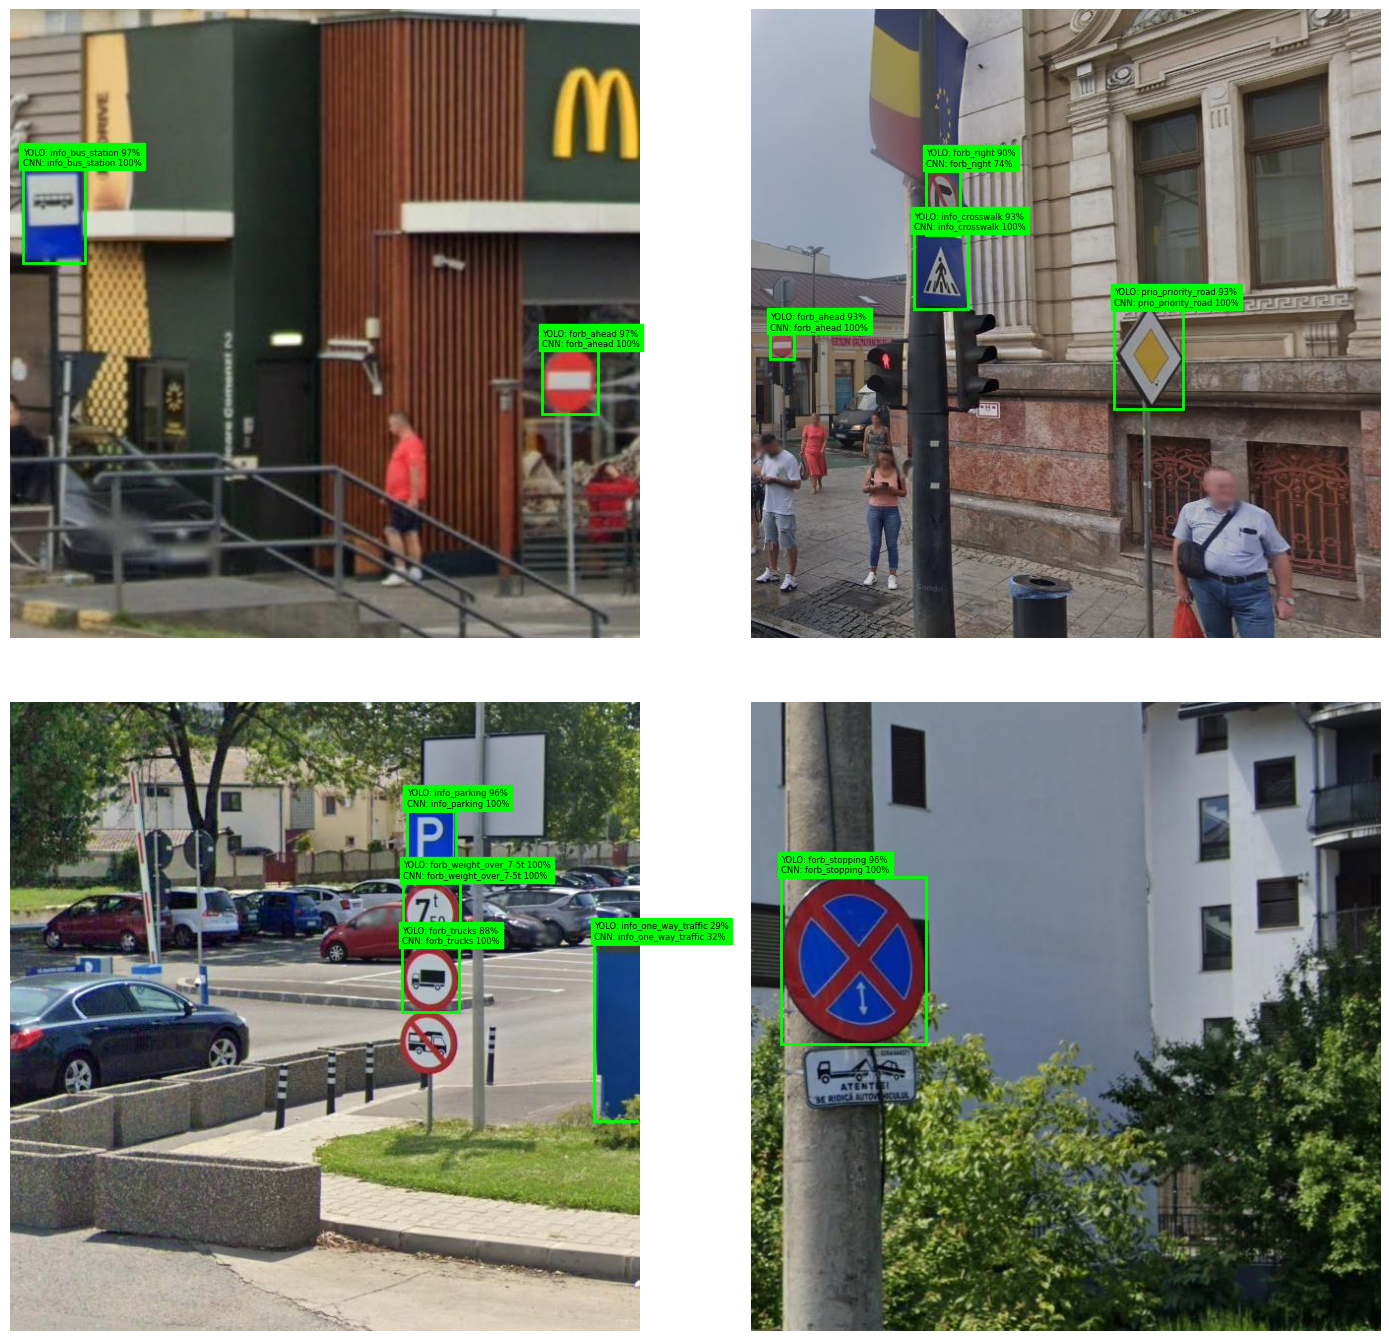

In [33]:
import matplotlib.patches as patches

# a few test photos: each box with the YOLO class and the CNN class (green = they agree, orange = they disagree)
random.seed(seed)
examplePhotos = random.sample(testPhotos, 4)

figure, axes = plt.subplots(2, 2, figsize=(14, 14))
for k in range(len(examplePhotos)):
    axis = axes[k // 2][k % 2]
    path = os.path.join(yoloDirectory, "images", "test", yoloFileName(examplePhotos[k]))
    axis.imshow(Image.open(path).convert("RGB"))

    for detection in detectAndClassify(path):
        left, top, right, bottom = detection["box"]
        if detection["yoloClass"] == detection["cnnClass"]:
            color = "lime"
        else:
            color = "orange"
        axis.add_patch(patches.Rectangle((left, top), right - left, bottom - top, fill=False, color=color, linewidth=2))
        label = "YOLO: " + labelNames[detection["yoloClass"]] + " " + str(round(100 * detection["yoloProbability"])) + "%\n"
        label += "CNN: " + labelNames[detection["cnnClass"]] + " " + str(round(100 * detection["cnnProbability"])) + "%"
        axis.text(left, top - 3, label, color="black", backgroundcolor=color, fontsize=6, verticalalignment="bottom")

    axis.axis("off")

plt.tight_layout()
plt.show()

## Partie 9 - Extension à la vidéo

La vidéo est traitée dans le **dashboard** ci-dessous (onglet « Vidéo ») :

Vidéo → images successives → YOLO → découpage des panneaux → CNN → boîtes et classes dessinées → vidéo MP4

Chaque image (ou une image sur N, pour aller plus vite) est analysée comme une photo, puis enregistrée ; `ffmpeg` assemble ensuite les images annotées en un fichier MP4, qui est enregistré dans `/content/videos/`. Les panneaux sont détectés image par image, sans suivi d'une image à l'autre.

## Dashboard de démonstration

Choix du modèle (MLP, CNN et leurs variantes de la partie 6, ou YOLO seul), puis analyse d'une image du jeu de test, d'une image envoyée ou d'une vidéo.

In [40]:
!pip install -q gradio
import gradio as gr
import cv2
import csv
import subprocess
import requests
import io
import time
from PIL import ImageDraw, ImageFont

YOLO_NAME = "YOLO 48 classes (sans CNN)"
PHOTO_MODE = "Photo complète (YOLO + classifieur)"
SIGN_MODE = "Panneau seul (classifieur)"
ALL_CLASSES = "Toutes les classes"

# every classifier we trained: MLP of part 2, CNN of part 3, and all the variants of part 6
classifiers = {}
classifiers["MLP - partie 2"] = {"model": mlp, "history": mlpHistory.history,
                                 "config": {"imageSize": 32, "learningRate": 0.001, "batchSize": 32, "dense": 128, "epochs": 20, "augmentation": False}}
classifiers["CNN - partie 3"] = {"model": cnn, "history": cnnHistory.history,
                                 "config": {"imageSize": 32, "learningRate": 0.001, "batchSize": 32, "filters": 32, "kernelSize": 3, "dense": 128, "dropout": 0.0, "epochs": 20, "augmentation": False}}
for row in results:
    config = dict(row["config"])
    config["epochs"] = row["epochs"]
    config["augmentation"] = "augm" in row["name"]
    classifiers[row["name"]] = {"model": row["model"], "history": row["history"].history, "config": config}

finalName = finalRow["name"]

# validation and test images resized to the size of each classifier (computed once per size)
dataOfSize = {}
def dataAtSize(size):
    if size not in dataOfSize:
        dataOfSize[size] = (resizeTo(signImages["valid"], size), resizeTo(signImages["test"], size))
    return dataOfSize[size]

# accuracy, macro precision / recall / F1, and the F1 of every class
def allScores(model, x, y):
    predictions = np.argmax(model.predict(x, verbose=0), axis=1)
    precisionTotal = 0
    recallTotal = 0
    f1OfClass = []
    for classNumber in range(numberOfClasses):
        truePositives = np.sum((predictions == classNumber) & (y == classNumber))
        falsePositives = np.sum((predictions == classNumber) & (y != classNumber))
        falseNegatives = np.sum((predictions != classNumber) & (y == classNumber))
        precision = truePositives / max(truePositives + falsePositives, 1)
        recall = truePositives / max(truePositives + falseNegatives, 1)
        precisionTotal += precision
        recallTotal += recall
        f1OfClass.append(2 * precision * recall / max(precision + recall, 1e-9))
    return {"accuracy": np.mean(predictions == y), "precision": precisionTotal / numberOfClasses,
            "recall": recallTotal / numberOfClasses, "f1": np.mean(f1OfClass), "f1OfClass": f1OfClass}

# validation and test metrics of a classifier (computed once)
metricsOf = {}
def getMetrics(name):
    if name not in metricsOf:
        entry = classifiers[name]
        xValidationSize, xTestSize = dataAtSize(entry["config"]["imageSize"])
        metricsOf[name] = (allScores(entry["model"], xValidationSize, yValidation), allScores(entry["model"], xTestSize, yTest))
    return metricsOf[name]

metricNames = {"accuracy": "Accuracy", "precision": "Précision (macro)", "recall": "Rappel (macro)", "f1": "F1 (macro)"}

def describeModel(name):
    if name == YOLO_NAME:
        text = "### " + name + "\n\n"
        text += "YOLOv8 nano pré-entraîné sur COCO, fine-tuné sur nos 48 classes : " + str(yoloEpochs) + " époques, images 640x640.\n\n"
        text += "| | Précision | Rappel | mAP50 | mAP50-95 |\n|---|---|---|---|---|\n"
        text += "| Photos de test | " + str(round(yoloMetrics.box.mp, 3)) + " | " + str(round(yoloMetrics.box.mr, 3)) + " | "
        text += str(round(yoloMetrics.box.map50, 3)) + " | " + str(round(yoloMetrics.box.map, 3)) + " |\n"
        return text

    entry = classifiers[name]
    validation, test = getMetrics(name)

    text = "### " + name
    if name == finalName:
        text += " (modèle final)"
    text += "\n\n**" + str(entry["model"].count_params()) + " poids entraînables.** YOLO trouve les panneaux, puis ce modèle les classe.\n\n"

    # one row of settings, then one row per set for the metrics
    keys = list(entry["config"])
    text += "| " + " | ".join(keys) + " |\n|" + "---|" * len(keys) + "\n"
    values = []
    for key in keys:
        values.append(str(entry["config"][key]))
    text += "| " + " | ".join(values) + " |\n\n"

    text += "| | " + " | ".join(metricNames.values()) + " |\n|---|" + "---|" * len(metricNames) + "\n"
    for setName, scores in [("Validation", validation), ("Test", test)]:
        values = []
        for metric in metricNames:
            values.append(str(round(scores[metric], 3)))
        text += "| " + setName + " | " + " | ".join(values) + " |\n"
    return text

In [41]:
# classifier probabilities for a list of cut-out signs (same preprocessing as the training images)
def predictSigns(classifierName, signs):
    entry = classifiers[classifierName]
    return entry["model"].predict(resizeTo(signs, entry["config"]["imageSize"]), verbose=0)

# one sign: the 5 most probable classes
def classifySign(sign, classifierName):
    if classifierName == YOLO_NAME:
        return {}, "YOLO a besoin d'une scène complète : choisissez un MLP ou un CNN pour classer un panneau seul."
    probabilities = predictSigns(classifierName, [sign])[0]
    top = {}
    for classNumber in np.argsort(probabilities)[::-1][:5]:
        top[labelNames[classNumber]] = float(probabilities[classNumber])
    return top, ""

# a full photo: YOLO finds the signs, the chosen classifier (or YOLO itself) gives their class
def analyzePhoto(photo, classifierName, confidence):
    result = yolo.predict(photo, conf=confidence, agnostic_nms=True, device="cpu", verbose=False)[0]
    boxesFound = result.boxes.xyxy.cpu().numpy()
    yoloClasses = result.boxes.cls.cpu().numpy()
    yoloConfidences = result.boxes.conf.cpu().numpy()

    keptBoxes = []
    signs = []
    labels = []
    for k in range(len(boxesFound)):
        left, top, right, bottom = boxesFound[k]
        if int(right) - int(left) < 1 or int(bottom) - int(top) < 1:
            continue
        keptBoxes.append((left, top, right, bottom))
        signs.append(photo.crop((int(left), int(top), int(right), int(bottom))))
        labels.append((labelNames[int(yoloClasses[k])], float(yoloConfidences[k])))

    if classifierName != YOLO_NAME and len(signs) > 0:
        probabilities = predictSigns(classifierName, signs)
        labels = []
        for k in range(len(signs)):
            classNumber = int(np.argmax(probabilities[k]))
            labels.append((labelNames[classNumber], float(probabilities[k][classNumber])))

    annotated = photo.copy()
    draw = ImageDraw.Draw(annotated)
    font = ImageFont.load_default(size=max(12, photo.width // 60))
    text = "| # | Classe | Probabilité |\n|---|---|---|\n"
    for k in range(len(keptBoxes)):
        left, top, right, bottom = keptBoxes[k]
        label = labels[k][0] + " " + str(round(100 * labels[k][1])) + "%"
        draw.rectangle((left, top, right, bottom), outline="lime", width=max(2, photo.width // 300))
        textBox = draw.textbbox((left, top), label, font=font)
        textHeight = textBox[3] - textBox[1]
        draw.rectangle((left, top - textHeight - 4, textBox[2] + 4, top), fill="lime")
        draw.text((left + 2, top - textHeight - 4), label, fill="black", font=font)
        text += "| " + str(k + 1) + " | " + labels[k][0] + " | " + str(round(100 * labels[k][1])) + " % |\n"

    if len(keptBoxes) == 0:
        text = "Aucun panneau détecté (essayez un seuil de confiance plus bas)."
    return annotated, text

In [42]:
# test set: full photos or cut-out signs, filtered by class
testPhotoList = []
for photo in boxesOfPhoto:
    if setOfPhoto[photo] == "test":
        testPhotoList.append(photo)

def candidates(mode, className):
    items = []
    if mode == PHOTO_MODE:
        for photo in testPhotoList:
            for box in boxesOfPhoto[photo]:
                if className == ALL_CLASSES or box["class"] == className:
                    items.append(photo)
                    break
    else:
        for i in range(len(signClasses["test"])):
            if className == ALL_CLASSES or signClasses["test"][i] == className:
                items.append(i)
    return items

def updateCount(mode, className):
    return gr.update(maximum=max(len(candidates(mode, className)) - 1, 0), value=0, label="Numéro (" + str(len(candidates(mode, className))) + " exemples)")

def randomNumber(mode, className):
    return random.randrange(max(len(candidates(mode, className)), 1))

def showTestExample(mode, className, number, classifierName, confidence):
    items = candidates(mode, className)
    if len(items) == 0:
        return None, {}, "Aucun exemple pour cette classe."
    item = items[int(number) % len(items)]

    if mode == PHOTO_MODE:
        photo = Image.open(os.path.join(datasetDirectory, item[0], boxesOfPhoto[item][0]["file"])).convert("RGB")
        annotated, text = analyzePhoto(photo, classifierName, confidence)
        trueClasses = []
        for box in boxesOfPhoto[item]:
            trueClasses.append(box["class"])
        return annotated, {}, "**Vraies classes :** " + ", ".join(trueClasses) + "\n\n" + text

    sign = signImages["test"][item]
    top, message = classifySign(sign, classifierName)
    text = "**Vraie classe :** " + signClasses["test"][item] + " (taille d'origine " + str(sign.width) + "x" + str(sign.height) + ")\n\n" + message
    return sign.resize((256, 256), Image.NEAREST), top, text

# an uploaded image or an image from a link
def analyzeImage(uploaded, url, mode, classifierName, confidence):
    if url:
        response = requests.get(url, timeout=20, headers={"User-Agent": "Mozilla/5.0"})
        image = Image.open(io.BytesIO(response.content)).convert("RGB")
    elif uploaded is not None:
        image = uploaded.convert("RGB")
    else:
        return None, {}, "Envoyez une image ou collez un lien."

    if mode == PHOTO_MODE:
        annotated, text = analyzePhoto(image, classifierName, confidence)
        return annotated, {}, text
    top, message = classifySign(image, classifierName)
    return image, top, message

In [43]:
videoDirectory = "/content/videos"
os.makedirs(videoDirectory, exist_ok=True)

# video: every frame (or one frame out of frameStep) is analysed and saved as an image,
# then ffmpeg compiles the images into an mp4 file
def processVideo(uploadedVideo, url, classifierName, confidence, frameStep, maxSeconds, progress=gr.Progress()):
    if url:
        videoPath = os.path.join(videoDirectory, "input.mp4")
        response = requests.get(url, timeout=60, headers={"User-Agent": "Mozilla/5.0"})
        with open(videoPath, "wb") as videoFile:
            videoFile.write(response.content)
    elif uploadedVideo:
        videoPath = uploadedVideo
    else:
        return None, None

    frameDirectory = os.path.join(videoDirectory, "frames")
    if os.path.exists(frameDirectory):
        shutil.rmtree(frameDirectory)
    os.makedirs(frameDirectory)

    capture = cv2.VideoCapture(videoPath)
    fps = capture.get(cv2.CAP_PROP_FPS)
    if fps <= 0:
        fps = 25
    lastFrame = int(maxSeconds * fps)
    totalFrames = min(int(capture.get(cv2.CAP_PROP_FRAME_COUNT)), lastFrame)

    frameNumber = 0
    savedFrames = 0
    while frameNumber < lastFrame:
        ok, frame = capture.read()
        if not ok:
            break
        if frameNumber % int(frameStep) == 0:
            photo = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            annotated, _ = analyzePhoto(photo, classifierName, confidence)
            annotated.save(os.path.join(frameDirectory, "frame_" + str(savedFrames).zfill(5) + ".jpg"))
            savedFrames += 1
            progress(frameNumber / max(totalFrames, 1), desc="image " + str(frameNumber) + " / " + str(totalFrames))
        frameNumber += 1
    capture.release()

    # H.264 so that browsers can play it; the size is made even, as the codec requires
    outputName = "video_" + classifierName.replace(" ", "_").replace("/", "-") + "_" + str(int(time.time())) + ".mp4"
    outputPath = os.path.join(videoDirectory, outputName)
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-framerate", str(fps / int(frameStep)),
                    "-i", os.path.join(frameDirectory, "frame_%05d.jpg"),
                    "-vf", "scale=trunc(iw/2)*2:trunc(ih/2)*2", "-c:v", "libx264", "-pix_fmt", "yuv420p", outputPath])
    return outputPath, outputPath

In [44]:
# comparison of the selected classifiers: curves of training, metrics, F1 of every class
def compareModels(names):
    names = [name for name in names if name in classifiers]
    colors = plt.cm.tab20

    lossFigure, lossAxis = plt.subplots(figsize=(10, 5))
    accuracyFigure, accuracyAxis = plt.subplots(figsize=(10, 5))
    for k in range(len(names)):
        history = classifiers[names[k]]["history"]
        lossAxis.plot(history["loss"], "--", color=colors(k % 20))
        lossAxis.plot(history["val_loss"], color=colors(k % 20), label=names[k])
        accuracyAxis.plot(history["accuracy"], "--", color=colors(k % 20))
        accuracyAxis.plot(history["val_accuracy"], color=colors(k % 20), label=names[k])
    for axis, title in [(lossAxis, "Loss (dashed = train, solid = validation)"), (accuracyAxis, "Accuracy (dashed = train, solid = validation)")]:
        axis.set_title(title)
        axis.set_xlabel("epoch")
        axis.legend(fontsize=7)

    # grouped bars: one group per metric, one bar per model, validation and test side by side
    metricsFigure, metricAxes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    width = 0.8 / max(len(names), 1)
    for setNumber, setName in [(0, "Validation"), (1, "Test")]:
        axis = metricAxes[setNumber]
        for k in range(len(names)):
            scores = getMetrics(names[k])[setNumber]
            positions = []
            heights = []
            for m, metric in enumerate(metricNames):
                positions.append(m + k * width)
                heights.append(scores[metric])
            axis.bar(positions, heights, width=width, color=colors(k % 20), label=names[k])
        axis.set_xticks([m + 0.4 - width / 2 for m in range(len(metricNames))])
        axis.set_xticklabels(list(metricNames.values()))
        axis.set_ylim(0, 1)
        axis.set_title(setName)
    metricAxes[1].legend(fontsize=7, loc="lower right")

    # F1 of every class on the validation set, from the hardest class (for the first model) to the easiest
    perClassFigure, perClassAxis = plt.subplots(figsize=(16, 5))
    if len(names) > 0:
        order = np.argsort(getMetrics(names[0])[0]["f1OfClass"])
        for k in range(len(names)):
            f1OfClass = getMetrics(names[k])[0]["f1OfClass"]
            perClassAxis.plot(range(numberOfClasses), [f1OfClass[c] for c in order], "o-", color=colors(k % 20), label=names[k], markersize=4)
        perClassAxis.set_xticks(range(numberOfClasses))
        perClassAxis.set_xticklabels([labelNames[c] for c in order], rotation=90, fontsize=7)
        perClassAxis.legend(fontsize=7)
    perClassAxis.set_ylim(0, 1.05)
    perClassAxis.set_title("F1 of every class (validation)")

    for figure in [lossFigure, accuracyFigure, metricsFigure, perClassFigure]:
        figure.tight_layout()
        plt.close(figure)
    return lossFigure, accuracyFigure, metricsFigure, perClassFigure

# YOLO training curves, saved by ultralytics in results.csv (one row per epoch)
def yoloCurves():
    with open("/content/runs/yolo/results.csv") as csvFile:
        rows = list(csv.DictReader(csvFile))
    def column(name):
        values = []
        for row in rows:
            for key in row:
                if key.strip() == name:
                    values.append(float(row[key]))
        return values

    figure, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot(column("train/box_loss"), "--", label="train")
    axes[0].plot(column("val/box_loss"), label="validation")
    axes[0].set_title("YOLO box loss (where)")
    axes[1].plot(column("train/cls_loss"), "--", label="train")
    axes[1].plot(column("val/cls_loss"), label="validation")
    axes[1].set_title("YOLO classification loss (which)")
    axes[2].plot(column("metrics/mAP50(B)"), label="mAP50")
    axes[2].plot(column("metrics/mAP50-95(B)"), label="mAP50-95")
    axes[2].plot(column("metrics/precision(B)"), label="precision")
    axes[2].plot(column("metrics/recall(B)"), label="recall")
    axes[2].set_title("YOLO validation metrics")
    for axis in axes:
        axis.set_xlabel("epoch")
        axis.legend()
    figure.tight_layout()
    plt.close(figure)
    return figure

In [45]:
# closes the dashboard of a previous run of this cell
gr.close_all()

defaultComparison = []
for name in ["MLP - partie 2", "CNN - partie 3", finalName]:
    if name not in defaultComparison:
        defaultComparison.append(name)

with gr.Blocks(title="Panneaux de signalisation") as dashboard:
    gr.Markdown("# Reconnaissance de panneaux de signalisation")

    with gr.Row():
        with gr.Column(scale=1):
            classifierChoice = gr.Dropdown(choices=list(classifiers) + [YOLO_NAME], value=finalName, label="Modèle")
            confidence = gr.Slider(0.05, 0.9, value=0.25, step=0.05, label="Seuil de confiance de YOLO")
        with gr.Column(scale=3):
            modelInfo = gr.Markdown()

    with gr.Tab("Jeu de test"):
        with gr.Row():
            testMode = gr.Radio([PHOTO_MODE, SIGN_MODE], value=PHOTO_MODE, label="Type d'image")
            classFilter = gr.Dropdown([ALL_CLASSES] + labelNames, value=ALL_CLASSES, label="Classe")
            number = gr.Slider(0, max(len(testPhotoList) - 1, 0), value=0, step=1, label="Numéro")
        with gr.Row():
            randomButton = gr.Button("Exemple aléatoire")
            testButton = gr.Button("Analyser", variant="primary")
        with gr.Row():
            testImage = gr.Image(label="Résultat")
            with gr.Column():
                testLabel = gr.Label(num_top_classes=5, label="Classes les plus probables")
                testText = gr.Markdown()

    with gr.Tab("Image (fichier ou lien)"):
        with gr.Row():
            uploadedImage = gr.Image(type="pil", label="Image")
            with gr.Column():
                imageUrl = gr.Textbox(label="ou lien direct vers une image (.jpg, .png)")
                imageMode = gr.Radio([PHOTO_MODE, SIGN_MODE], value=PHOTO_MODE, label="Type d'image")
                imageButton = gr.Button("Analyser", variant="primary")
        with gr.Row():
            imageResult = gr.Image(label="Résultat")
            with gr.Column():
                imageLabel = gr.Label(num_top_classes=5, label="Classes les plus probables")
                imageText = gr.Markdown()

    with gr.Tab("Vidéo"):
        with gr.Row():
            uploadedVideo = gr.Video(label="Vidéo")
            with gr.Column():
                videoUrl = gr.Textbox(label="ou lien direct vers une vidéo (.mp4)")
                frameStep = gr.Slider(1, 10, value=2, step=1, label="Analyser une image sur")
                maxSeconds = gr.Slider(1, 60, value=15, step=1, label="Durée maximale analysée (secondes)")
                videoButton = gr.Button("Analyser la vidéo", variant="primary")
        with gr.Row():
            videoResult = gr.Video(label="Vidéo annotée")
            videoFile = gr.File(label="Fichier mp4")

    with gr.Tab("Comparaison"):
        comparedModels = gr.CheckboxGroup(choices=list(classifiers), value=defaultComparison, label="Modèles comparés")
        compareButton = gr.Button("Comparer", variant="primary")
        metricsPlot = gr.Plot(label="Métriques")
        with gr.Row():
            lossPlot = gr.Plot(label="Loss")
            accuracyPlot = gr.Plot(label="Accuracy")
        perClassPlot = gr.Plot(label="F1 par classe")
        gr.Markdown("### YOLO")
        yoloPlot = gr.Plot(label="Entraînement de YOLO")

    classifierChoice.change(describeModel, classifierChoice, modelInfo)
    dashboard.load(describeModel, classifierChoice, modelInfo)

    testMode.change(updateCount, [testMode, classFilter], number)
    classFilter.change(updateCount, [testMode, classFilter], number)
    randomButton.click(randomNumber, [testMode, classFilter], number).then(
        showTestExample, [testMode, classFilter, number, classifierChoice, confidence], [testImage, testLabel, testText])
    testButton.click(showTestExample, [testMode, classFilter, number, classifierChoice, confidence], [testImage, testLabel, testText])

    imageButton.click(analyzeImage, [uploadedImage, imageUrl, imageMode, classifierChoice, confidence], [imageResult, imageLabel, imageText])
    videoButton.click(processVideo, [uploadedVideo, videoUrl, classifierChoice, confidence, frameStep, maxSeconds], [videoResult, videoFile])

    compareButton.click(compareModels, comparedModels, [lossPlot, accuracyPlot, metricsPlot, perClassPlot])
    dashboard.load(compareModels, comparedModels, [lossPlot, accuracyPlot, metricsPlot, perClassPlot])
    dashboard.load(yoloCurves, None, yoloPlot)

# share=True gives a public link (valid 72 h), needed when the notebook runs on Colab from VS Code
dashboard.launch(share=True)

Closing server running on port: 7860
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4a1a64fdb2a3cb1fd9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
